# ETH Monte Carlo price simulation

This notebook models a range of possible future ETH prices with Monte Carlo simulation. It:

1. **Data:** downloads daily ETH-USD history from 2016 to today and caches it, then fetches the live price and circulating supply.
2. **Exploratory analysis:** looks at realized volatility, fat tails and drawdowns.
3. **Models:** simulates thousands of price paths with five models that share one function signature: GBM, Student-t, block bootstrap, GARCH-t and a GMM regime-switching model. Optionally (`VOL_UNCERTAINTY`), each path can get its own volatility, drawn from how wrong past volatility estimates have been.
4. **Outputs:** summarizes the paths as fan charts, end-price percentiles, implied market caps, the probability of ending above or touching key prices, and expected drawdowns.
5. **Strategy tester:** compares three simple trading rules across all simulated paths.
6. **Calibration check:** backtests every model, with and without volatility uncertainty, from hundreds of historical start dates at four horizons. It reports interval coverage, PIT histograms and CRPS scores, and checks which volatility lookback window and GARCH persistence forecast best.

> **This is not investment advice.** These are statistical scenarios built from past price behaviour, not forecasts. All parameters are in the config cell below. Rerun top to bottom after changing them.

In [1]:
# ================================ CONFIG ================================
# Simulation
HORIZON_DAYS      = 365        # horizon in calendar days (ETH trades 24/7, so 1 year = 365 steps)
N_PATHS           = 10_000     # Monte Carlo paths per model
DRIFT             = 0.0        # annual arithmetic drift mu of the price. 0 => E[S_T] = S_0 (martingale)
VOL_OVERRIDE      = None       # annual volatility, e.g. 0.70. None => estimate from history
VOL_LOOKBACK_DAYS = 365        # trailing window for volatility when VOL_OVERRIDE is None (backtest winner, section 6.1)
VOL_UNCERTAINTY   = False      # True => each path gets its own vol, drawn from past vol-forecast errors (didn't help the backtest)
DRIFT_SD          = 0.0        # optional: per-path annual drift ~ Normal(DRIFT, DRIFT_SD). 0 => same drift everywhere
SEED              = 42         # master random seed (every model draws from its own stream derived from it)

# Price levels to report probabilities for (USD). 4,946 = ETH all-time high.
ATH_PRICE  = 4_946                # intraday all-time high (Aug 2025)
THRESHOLDS = [1_000, 1_500, 2_000, 3_000, ATH_PRICE, 8_000, 10_000]
PERCENTILES = [5, 25, 50, 75, 95]

# Model settings
BLOCK_LENGTH   = 10            # block-bootstrap block length (days)
GMM_COMPONENTS = [2, 3]        # candidate numbers of regimes, chosen by BIC
GMM_WINDOW     = 30            # rolling window (days) for the regime features
GARCH_PERSISTENCE = 0.95       # alpha + beta of the GARCH-t model (unconstrained MLE hits 1.0; see 3.3 and 6.1)

# Strategy tester
LADDER = [(1.5, 0.25), (2.0, 0.25), (3.0, 0.25)]  # (multiple of entry, fraction of initial ETH sold)
DCA_INITIAL_FRACTION = 0.50    # share of capital invested on day 0; the rest is held as cash
DCA_N_TRANCHES       = 5       # that cash is split into this many equal tranches
DCA_TRIGGER_DROP     = 0.20    # buy a tranche when price is 20% below its running peak (peak resets after each buy)

# Calibration backtest
CAL_HORIZONS       = [30, 90, 180, 365]   # forecast horizons checked (days)
CAL_STEP_DAYS      = 7                    # spacing between historical start dates
CAL_N_PATHS        = 2_000                # paths per start date and model
CAL_REFIT_DAYS     = 28                   # refit GARCH / GMM / Student-t parameters this often (they're slow to fit)
CAL_LOOKBACK_GRID  = [90, 180, 365, 730, 1095]   # volatility lookback windows compared
CAL_PERSISTENCE_GRID = [0.95, 0.98, 0.99]        # GARCH persistence values compared
CAL_DRIFT_SD_GRID  = [0.5, 1.0]           # per-path drift uncertainty (annual sd) tested on GBM
CAL_MIN_VOL_ERRORS = 90                   # days of vol-forecast-error history needed before vol uncertainty is usable

# Data / caching
HISTORY_START      = "2016-01-01"
DATA_DIR           = "data"
CACHE_MAX_AGE_DAYS = 1         # if the cached history is this fresh, don't go online for it
FORCE_OFFLINE      = False     # True => never touch the network, use cached files only

In [2]:
import json
import time
import zlib
import warnings
import logging
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from scipy import stats
from arch import arch_model
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from IPython.display import display

try:
    import yfinance as yf
except ImportError:          # CoinGecko / Coinbase fallbacks still work
    yf = None

warnings.filterwarnings("ignore", category=FutureWarning)
logging.getLogger("yfinance").setLevel(logging.CRITICAL)   # silence cookie/crumb chatter
pd.set_option("display.width", 160)

ANN = 365                                   # periods per year for a 24/7 asset
np.random.seed(SEED)                        # belt and braces; all sampling below uses explicit Generators


def rng_for(name: str) -> np.random.Generator:
    """Independent, reproducible random stream per model/experiment, derived from SEED."""
    return np.random.default_rng([SEED, zlib.crc32(name.encode())])


# ---- chart style: light surface, recessive grid/axes, thin marks -------------------------
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # categorical slots 1-5 (CVD-validated order)
BLUE_RAMP = {"band_outer": "#cde2fb", "band_inner": "#86b6ef", "median": "#184f95"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "figure.figsize": (11, 4.5),
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 1.6,
    "axes.prop_cycle": plt.cycler(color=SERIES),
})

usd_fmt = mticker.FuncFormatter(lambda x, _: f"${x:,.0f}" if x >= 1 else f"${x:,.2f}")
pct_fmt = mticker.PercentFormatter(1.0, decimals=0)


def log_price_axis(ax):
    """Log-scale price axis with readable dollar ticks."""
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(mticker.LogLocator(base=10, subs=(1, 2, 5)))
    ax.yaxis.set_major_formatter(usd_fmt)
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())


def fmt_usd(x):
    return f"${x:,.0f}"


def fmt_bn(x):
    return f"${x / 1e9:,.0f}B"

## 1. Data

**Price history.** The notebook combines three sources, in priority order:

- **Yahoo Finance via `yfinance`**: the primary source. Its `ETH-USD` series starts on 2017-11-09.
- **Coinbase Exchange public candles**: backfill for 2016 to 2017-11, before Yahoo's series begins. ETH-USD trades on Coinbase from 2016-05-18, so that is where the history starts. Coinbase is also the full-history fallback if Yahoo is down.
- **CoinGecko**: fallback for the most recent 365 days. The free CoinGecko API serves only one year of history.

The merged series is cached to `data/eth_usd_daily.csv`. The cache is reused when it is fresh, and used automatically when every source is unreachable, so reruns work offline. The current, still-incomplete UTC day is dropped from the history.

**Live snapshot.** The current price and circulating supply come from CoinGecko, with `yfinance` as the fallback. The last successful snapshot is cached to `data/eth_live_snapshot.json` for offline reruns, and the notebook prints a warning when it falls back to the cache.

In [3]:
DATA = Path(DATA_DIR)
DATA.mkdir(exist_ok=True)
PRICE_CACHE = DATA / "eth_usd_daily.csv"
SNAPSHOT_CACHE = DATA / "eth_live_snapshot.json"
HEADERS = {"User-Agent": "eth-monte-carlo-notebook/1.0"}
TODAY = pd.Timestamp.now(tz="UTC").tz_localize(None).normalize()    # start of the current UTC day


def fetch_yahoo(start: str) -> pd.Series:
    if yf is None:
        raise RuntimeError("yfinance is not installed")
    df = yf.download("ETH-USD", start=start, interval="1d", auto_adjust=False,
                     progress=False, threads=False)
    if df is None or df.empty:
        raise RuntimeError("yfinance returned no rows")
    close = df["Close"]
    if isinstance(close, pd.DataFrame):          # yfinance returns MultiIndex columns
        close = close.iloc[:, 0]
    idx = pd.DatetimeIndex(close.index)
    if idx.tz is not None:
        idx = idx.tz_convert(None)
    return pd.Series(close.to_numpy(float), index=idx.normalize()).dropna()


def fetch_coinbase(start, end) -> pd.Series:
    """Daily closes (00:00 UTC candles) from Coinbase Exchange, 300 candles per request."""
    url = "https://api.exchange.coinbase.com/products/ETH-USD/candles"
    rows, t, end = [], pd.Timestamp(start), pd.Timestamp(end)
    while t <= end:
        t2 = min(t + pd.Timedelta(days=299), end)
        r = requests.get(url, headers=HEADERS, timeout=30, params={
            "granularity": 86400,
            "start": t.strftime("%Y-%m-%dT00:00:00Z"),
            "end": t2.strftime("%Y-%m-%dT00:00:00Z")})
        r.raise_for_status()
        rows += r.json()
        t = t2 + pd.Timedelta(days=1)
        time.sleep(0.35)                         # stay well inside the public rate limit
    if not rows:
        raise RuntimeError("Coinbase returned no candles")
    df = pd.DataFrame(rows, columns=["time", "low", "high", "open", "close", "volume"])
    idx = pd.DatetimeIndex(pd.to_datetime(df["time"], unit="s")).normalize()
    s = pd.Series(df["close"].to_numpy(float), index=idx)
    return s[~s.index.duplicated()].sort_index()


def fetch_coingecko_recent(days: int = 365) -> pd.Series:
    """Last `days` daily prices. CoinGecko's 00:00 UTC point ~ the previous day's close."""
    r = requests.get("https://api.coingecko.com/api/v3/coins/ethereum/market_chart",
                     params={"vs_currency": "usd", "days": days, "interval": "daily"},
                     headers=HEADERS, timeout=30)
    r.raise_for_status()
    p = pd.DataFrame(r.json()["prices"], columns=["ms", "price"])
    idx = pd.DatetimeIndex(pd.to_datetime(p["ms"], unit="ms")).normalize() - pd.Timedelta(days=1)
    s = pd.Series(p["price"].to_numpy(float), index=idx)
    return s[~s.index.duplicated(keep="first")].sort_index()


def load_price_history() -> pd.DataFrame:
    cache = None
    if PRICE_CACHE.exists():
        cache = pd.read_csv(PRICE_CACHE, parse_dates=["date"], index_col="date")
        age = (TODAY - cache.index.max()).days
        if FORCE_OFFLINE or age <= CACHE_MAX_AGE_DAYS:
            print(f"Using cached history ({PRICE_CACHE}, last close {cache.index.max().date()}).")
            return cache
    elif FORCE_OFFLINE:
        raise FileNotFoundError(f"FORCE_OFFLINE=True but {PRICE_CACHE} does not exist")

    parts, yahoo = [], None
    try:
        yahoo = fetch_yahoo(HISTORY_START)
        parts.append(("yahoo", yahoo))
        print(f"yfinance:  {len(yahoo):,} days from {yahoo.index.min().date()}")
    except Exception as e:
        print(f"WARNING: yfinance failed ({type(e).__name__}: {e})")

    backfill_end = (yahoo.index.min() - pd.Timedelta(days=1)) if yahoo is not None else TODAY - pd.Timedelta(days=1)
    if pd.Timestamp(HISTORY_START) <= backfill_end:
        try:
            cb = fetch_coinbase(HISTORY_START, backfill_end)
            parts.append(("coinbase", cb))
            print(f"Coinbase:  {len(cb):,} days from {cb.index.min().date()} to {cb.index.max().date()}")
        except Exception as e:
            print(f"WARNING: Coinbase failed ({type(e).__name__}: {e})")

    if yahoo is None:
        try:
            cg = fetch_coingecko_recent(365)
            parts.append(("coingecko", cg))
            print(f"CoinGecko: {len(cg):,} recent days")
        except Exception as e:
            print(f"WARNING: CoinGecko failed ({type(e).__name__}: {e})")

    if not parts:
        if cache is None:
            raise RuntimeError("No data source reachable and no cache available.")
        print("WARNING: all sources unreachable - using the (stale) cache.")
        return cache

    df = None
    for name, s in parts:                       # earlier parts take priority
        piece = pd.DataFrame({"close": s, "source": name})
        df = piece if df is None else df.combine_first(piece)
    if cache is not None:                       # keep any cached days the sources didn't return
        df = df.combine_first(cache[["close", "source"]])

    df = df[(df.index >= pd.Timestamp(HISTORY_START)) & (df.index < TODAY)].sort_index()
    full_idx = pd.date_range(df.index.min(), df.index.max(), freq="D")
    n_missing = len(full_idx) - len(df)
    df = df.reindex(full_idx)
    df["source"] = df["source"].fillna("ffill")
    df["close"] = df["close"].ffill()
    if n_missing:
        print(f"Forward-filled {n_missing} missing day(s).")
    df.index.name = "date"
    df.to_csv(PRICE_CACHE)
    print(f"Cached {len(df):,} days to {PRICE_CACHE}")
    return df


def fetch_live_snapshot() -> dict:
    now = dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")
    snap, errors = None, []
    if not FORCE_OFFLINE:
        try:
            r = requests.get("https://api.coingecko.com/api/v3/coins/ethereum", headers=HEADERS, timeout=30,
                             params={"localization": "false", "tickers": "false", "market_data": "true",
                                     "community_data": "false", "developer_data": "false", "sparkline": "false"})
            r.raise_for_status()
            m = r.json()["market_data"]
            snap = {"price": float(m["current_price"]["usd"]),
                    "circulating_supply": float(m["circulating_supply"]),
                    "source": "CoinGecko", "fetched_at_utc": now}
        except Exception as e:
            errors.append(f"CoinGecko: {type(e).__name__}: {e}")
        if snap is None and yf is not None:
            try:
                t = yf.Ticker("ETH-USD")
                price = float(t.fast_info["last_price"])
                supply = (t.info or {}).get("circulatingSupply")
                if not supply:
                    raise RuntimeError("no circulatingSupply in yfinance info")
                snap = {"price": price, "circulating_supply": float(supply),
                        "source": "yfinance", "fetched_at_utc": now}
            except Exception as e:
                errors.append(f"yfinance: {type(e).__name__}: {e}")
    if snap is not None:
        SNAPSHOT_CACHE.write_text(json.dumps(snap, indent=2))
        return snap
    for e in errors:
        print("WARNING:", e)
    if SNAPSHOT_CACHE.exists():
        snap = json.loads(SNAPSHOT_CACHE.read_text())
        snap["source"] += " (cached)"
        print(f"WARNING: live fetch unavailable - using cached snapshot from {snap['fetched_at_utc']}")
        return snap
    raise RuntimeError("Could not fetch the live price/supply and no cached snapshot exists.")


history = load_price_history()
close = history["close"].astype(float)
snapshot = fetch_live_snapshot()
S0 = snapshot["price"]
SUPPLY = snapshot["circulating_supply"]

Using cached history (data/eth_usd_daily.csv, last close 2026-11-04).


In [4]:
log_ret = np.log(close).diff().dropna()
log_ret.name = "log_return"

overview = pd.Series({
    "History": f"{close.index.min().date()} to {close.index.max().date()} ({len(close):,} days)",
    "Rows by source": ", ".join(f"{k}: {v:,}" for k, v in history["source"].value_counts().items()),
    "Daily log returns": f"{len(log_ret):,}",
    "Last daily close": fmt_usd(close.iloc[-1]),
    f"Live price ({snapshot['source']})": f"${S0:,.2f}",
    "Circulating supply": f"{SUPPLY:,.0f} ETH",
    "Implied market cap": fmt_bn(S0 * SUPPLY),
    "Snapshot time (UTC)": snapshot["fetched_at_utc"],
}, name="value")
display(overview.to_frame())

,value
History,"2016-05-18 to 2026-11-04 (3,823 days)"
Rows by source,"yahoo: 3,283, coinbase: 538, ffill: 2"
Daily log returns,"3,822"
Last daily close,"$2,422"
Live price (CoinGecko),"$2,363.24"
Circulating supply,"122,192,072 ETH"
Implied market cap,$289B
Snapshot time (UTC),2026-11-05T14:51:15+00:00


## 2. Exploratory analysis

### 2.1 Realized volatility
Volatility is annualized as the standard deviation of daily log returns × √365, since crypto trades every day of the year.

,annualized volatility
Full history (2016-today),91.4%
Last 365 days,60.0%
Last 365 days (model default),60.0%
-> Used in simulations,60.0%


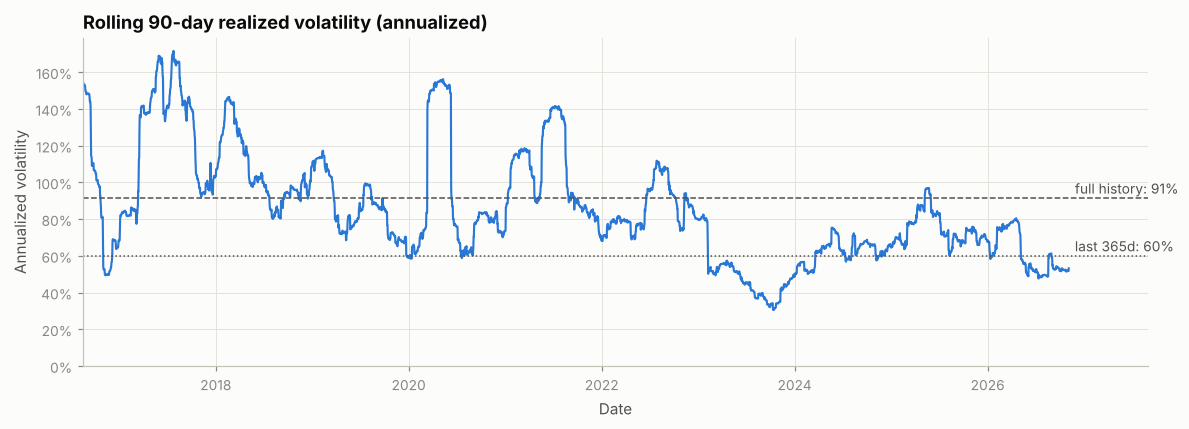

In [5]:
vol_full = log_ret.std() * np.sqrt(ANN)
vol_365 = log_ret.iloc[-365:].std() * np.sqrt(ANN)
vol_lookback = log_ret.iloc[-VOL_LOOKBACK_DAYS:].std() * np.sqrt(ANN)
SIGMA_ANNUAL = VOL_OVERRIDE if VOL_OVERRIDE is not None else vol_lookback

vol_table = pd.DataFrame({"annualized volatility": {
    f"Full history ({close.index.min().year}-today)": vol_full,
    "Last 365 days": vol_365,
    f"Last {VOL_LOOKBACK_DAYS} days (model default)": vol_lookback,
    "-> Used in simulations": SIGMA_ANNUAL,
}})
display(vol_table.style.format("{:.1%}"))

roll90 = log_ret.rolling(90).std() * np.sqrt(ANN)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(roll90.index, roll90, color=SERIES[0], lw=1.4)
for level, label, ls in [(vol_full, "full history", "--"), (vol_365, "last 365d", ":")]:
    ax.axhline(level, color=INK2, lw=1, ls=ls)
    ax.annotate(f"{label}: {level:.0%}", (roll90.index[-1], level), xytext=(4, 3),
                textcoords="offset points", color=INK2, fontsize=9, ha="left")
ax.yaxis.set_major_formatter(pct_fmt)
ax.set_ylim(0, None)
ax.set_title("Rolling 90-day realized volatility (annualized)")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized volatility")
ax.set_xlim(roll90.dropna().index[0], roll90.index[-1] + pd.Timedelta(days=300))
plt.tight_layout()
plt.show()

### 2.2 Return distribution vs a fitted normal
If returns were normal, the histogram would follow the normal curve and the QQ plot would be a straight line. Fat tails show up as excess density far from zero on the log-scale histogram, and as the QQ points bending away from the line at both ends.

,value
Daily mean,0.1364%
Daily std,4.786%
Skewness (normal = 0),-0.40
Excess kurtosis (normal = 0),9.29
Jarque-Bera p-value,0.0e+00
Worst day,-55.1% (2020-03-12)
Best day,26.3% (2017-05-19)


,observed days,expected if normal
|move| > 3σ,75,10.32
|move| > 4σ,25,0.24
|move| > 5σ,8,0.00


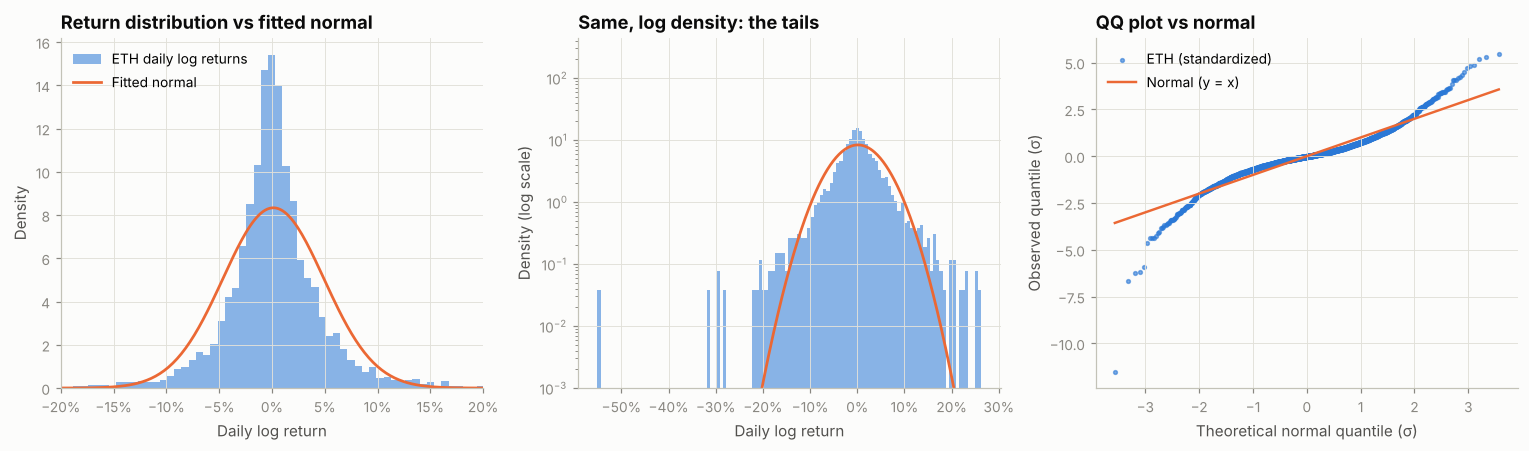

In [6]:
mu_hat, sd_hat = log_ret.mean(), log_ret.std()
skew = stats.skew(log_ret)
ex_kurt = stats.kurtosis(log_ret, fisher=True)
jb = stats.jarque_bera(log_ret)
z = (log_ret - mu_hat) / sd_hat

dist_table = pd.DataFrame({"value": {
    "Daily mean": f"{mu_hat:.4%}",
    "Daily std": f"{sd_hat:.3%}",
    "Skewness (normal = 0)": f"{skew:.2f}",
    "Excess kurtosis (normal = 0)": f"{ex_kurt:.2f}",
    "Jarque-Bera p-value": f"{jb.pvalue:.1e}",
    "Worst day": f"{log_ret.min():.1%} ({log_ret.idxmin().date()})",
    "Best day": f"{log_ret.max():.1%} ({log_ret.idxmax().date()})",
}})
tails = pd.DataFrame({
    "observed days": [(z.abs() > k).sum() for k in (3, 4, 5)],
    "expected if normal": [len(z) * 2 * stats.norm.sf(k) for k in (3, 4, 5)],
}, index=["|move| > 3σ", "|move| > 4σ", "|move| > 5σ"])
display(dist_table)
display(tails.style.format({"expected if normal": "{:.2f}"}))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
grid = np.linspace(log_ret.min(), log_ret.max(), 400)
bins = np.linspace(log_ret.min(), log_ret.max(), 120)
for ax, logy in zip(axes[:2], [False, True]):
    ax.hist(log_ret, bins=bins, density=True, color=SERIES[0], alpha=0.55, label="ETH daily log returns")
    ax.plot(grid, stats.norm.pdf(grid, mu_hat, sd_hat), color=SERIES[1], lw=1.8, label="Fitted normal")
    ax.xaxis.set_major_formatter(pct_fmt)
    ax.set_xlabel("Daily log return")
    ax.set_ylabel("Density" + (" (log scale)" if logy else ""))
    if logy:
        ax.set_yscale("log")
        ax.set_ylim(1e-3, None)
        ax.set_title("Same, log density: the tails")
    else:
        ax.set_xlim(-0.2, 0.2)
        ax.set_title("Return distribution vs fitted normal")
        ax.legend(loc="upper left")
(osm, osr), (slope, intercept, _) = stats.probplot(z, dist="norm")
axes[2].scatter(osm, osr, s=6, color=SERIES[0], alpha=0.6, label="ETH (standardized)")
lim = np.array([osm.min(), osm.max()])
axes[2].plot(lim, lim, color=SERIES[1], lw=1.6, label="Normal (y = x)")
axes[2].set_title("QQ plot vs normal")
axes[2].set_xlabel("Theoretical normal quantile (σ)")
axes[2].set_ylabel("Observed quantile (σ)")
axes[2].legend(loc="upper left")
plt.tight_layout()
plt.show()

### 2.3 Drawdowns
Drawdown is the percentage fall from the highest close reached so far. The table lists the deepest distinct episodes. Each episode runs from a peak, down to its trough, and back to a recovery above the old peak, if that has happened yet.

,peak date,peak,trough date,trough,drawdown,days peak to trough,recovered,days to recover
1,2018-01-13,"$1,396",2018-12-14,$84,-94.0%,335,2021-02-02,781
2,2021-11-08,"$4,812",2022-06-18,$994,-79.4%,222,2025-08-22,"1,161"
3,2016-06-16,$21,2016-12-05,$7,-67.8%,172,2017-03-11,96
4,2025-08-22,"$4,831",2026-06-25,"$1,565",-67.6%,307,not yet,-
5,2017-06-12,$397,2017-07-16,$156,-60.8%,34,2017-11-23,130
6,2021-05-11,"$4,169",2021-07-20,"$1,788",-57.1%,70,2021-10-23,95
7,2021-02-19,"$1,960",2021-02-28,"$1,416",-27.8%,9,2021-04-01,32
8,2017-03-16,$46,2017-03-18,$34,-26.8%,2,2017-03-24,6


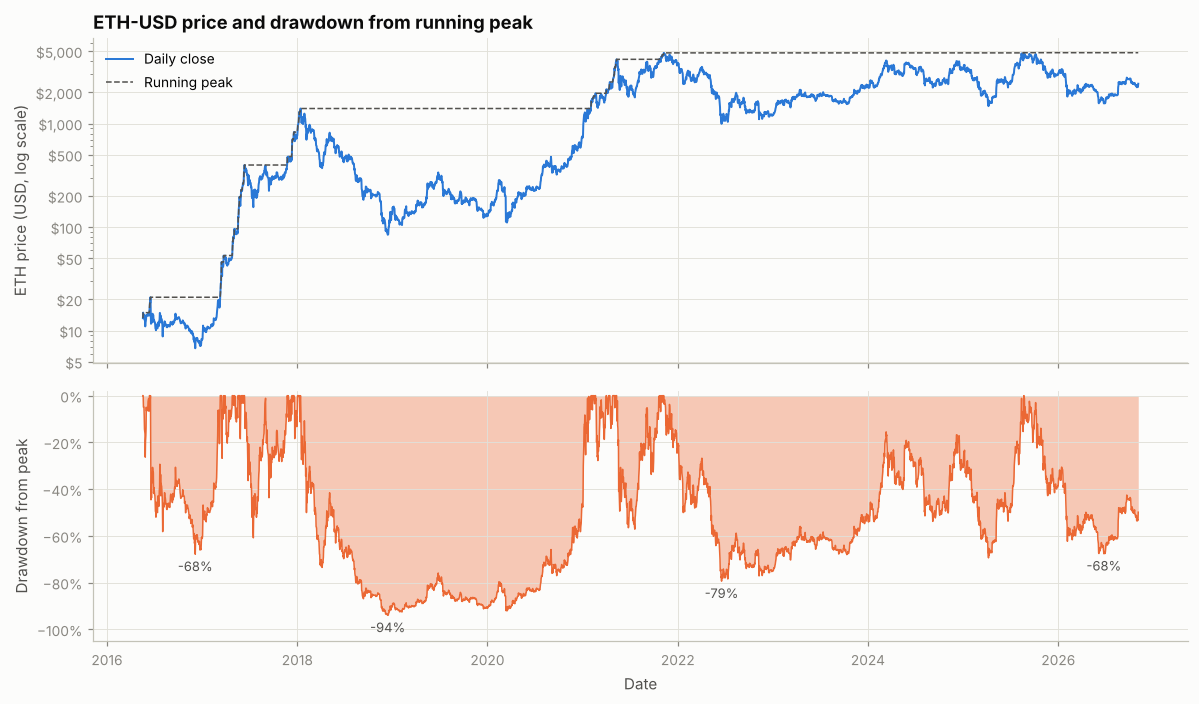

In [7]:
running_peak = close.cummax()
drawdown = close / running_peak - 1


def drawdown_episodes(close: pd.Series) -> pd.DataFrame:
    peak = close.cummax()
    dd = close / peak - 1
    new_high = dd == 0
    episode_id = new_high.cumsum()             # each new high starts a new episode
    rows = []
    for _, seg in dd.groupby(episode_id):
        if seg.min() >= 0:
            continue
        peak_date = seg.index[0]
        trough_date = seg.idxmin()
        after = close.loc[trough_date:]
        rec = after[after >= close.loc[peak_date]]
        rec_date = rec.index[0] if len(rec) else pd.NaT
        rows.append({"peak date": peak_date.date(), "peak": close.loc[peak_date],
                     "trough date": trough_date.date(), "trough": close.loc[trough_date],
                     "drawdown": seg.min(),
                     "days peak to trough": (trough_date - peak_date).days,
                     "recovered": rec_date.date() if pd.notna(rec_date) else "not yet",
                     "days to recover": (rec_date - trough_date).days if pd.notna(rec_date) else np.nan})
    return pd.DataFrame(rows).sort_values("drawdown").reset_index(drop=True)


dd_table = drawdown_episodes(close).head(8)
dd_table.index = dd_table.index + 1
display(dd_table.style.format({"peak": "${:,.0f}", "trough": "${:,.0f}", "drawdown": "{:.1%}",
                               "days to recover": "{:,.0f}"}, na_rep="-"))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
ax1.plot(close.index, close, color=SERIES[0], lw=1.3, label="Daily close")
ax1.plot(running_peak.index, running_peak, color=INK2, lw=1, ls="--", label="Running peak")
log_price_axis(ax1)
ax1.set_ylabel("ETH price (USD, log scale)")
ax1.set_title("ETH-USD price and drawdown from running peak")
ax1.legend(loc="upper left")
ax2.fill_between(drawdown.index, drawdown, 0, color=SERIES[1], alpha=0.35, lw=0)
ax2.plot(drawdown.index, drawdown, color=SERIES[1], lw=1)
ax2.yaxis.set_major_formatter(pct_fmt)
ax2.set_ylabel("Drawdown from peak")
ax2.set_xlabel("Date")
for _, row in dd_table.head(4).iterrows():
    d = pd.Timestamp(row["trough date"])
    ax2.annotate(f"{row['drawdown']:.0%}", (d, row["drawdown"]), xytext=(0, -11),
                 textcoords="offset points", ha="center", fontsize=8.5, color=INK2)
ax2.set_ylim(-1.05, 0.02)
plt.tight_layout()
plt.show()

## 3. Simulation models

All five models have the same signature:

```python
simulate_x(s0, hist_returns, horizon, n_paths, rng, drift=..., vol=..., fit_returns=None) -> ndarray of shape (n_paths, horizon + 1)
```

- **Output:** column 0 is today's price.
- **`hist_returns`:** returns up to the forecast date. Used for anything that changes daily: today's GARCH variance, today's regime and the bootstrap pool.
- **`fit_returns`:** returns used to estimate the slow-moving parameters: the GARCH α and ν, the Student-t degrees of freedom, and the GMM regimes. Defaults to `hist_returns`. The backtest in section 6 passes an older slice so it only has to refit monthly.
- **`drift` and `vol`:** annual drift and annual volatility. Either one number, or an array with one value per path. Per-path values are how volatility uncertainty (section 3.1) enters every model.

To keep the comparison fair, every model is centered on the same daily log drift, `(drift - vol²/2) / 365`, and scaled to the same volatility, `vol`. With `DRIFT = 0` the expected price stays flat, while the median price drifts down slightly, which is how a volatile log-normal asset behaves. The models differ in the shape of their returns and in how volatility moves over time:

| Model | Daily returns | What it captures |
|---|---|---|
| **GBM** | i.i.d. normal | Baseline. Thin tails and no memory. |
| **Student-t** | i.i.d. Student-t, with degrees of freedom from the GARCH-t fit | Fat-tailed shocks, but no memory. |
| **Block bootstrap** | Resampled 10-day blocks of real, demeaned history | Real tail shape plus short-run volatility clustering. |
| **GARCH-t** | Student-t shocks, with a volatility that reacts to each shock | Starts from today's volatility. Big moves raise the next days' volatility, which then decays back to the long-run level. |
| **GMM regimes** | Normal within each regime, with a Markov chain switching between regimes | Long calm, bull and crash phases. Starts from the current regime. |

The central volatility comes from the last `VOL_LOOKBACK_DAYS` unless `VOL_OVERRIDE` is set.

### 3.1 Volatility uncertainty
The first version of this notebook gave every path the same volatility. Its backtest showed the 95% bands were too narrow, because next year's volatility can be far from the trailing estimate. This section measures that error directly:

1. **Collect past errors.** For every past day, compare the trailing `VOL_LOOKBACK_DAYS` volatility estimate with the volatility actually realized over the following 365 days.
2. **Summarize them.** The log of that ratio is the volatility-forecast error.
3. **Draw a volatility per path.** Each path gets its own volatility: the central estimate times `exp(error)`, with the error drawn from that history.

The errors are demeaned on a log scale, so they widen the spread of outcomes without moving the central estimate. Every model gets the same set of per-path volatilities, so the models stay comparable. `DRIFT_SD` optionally does the same for drift.

**This is off by default.** The backtest in section 6 runs every model with and without it, and it did not improve calibration at any horizon. The 1-year misses come from ETH rising far more than a zero-drift model expects, not from a wrong volatility, and a ±25% error in volatility can't produce a 10× year. Set `VOL_UNCERTAINTY = True` to include it anyway. The chart below shows what it would draw either way.

3,093 daily vol-forecast errors (365d trailing estimate vs next 365d realized). Std of log error: 0.24, i.e. next year's vol is typically within ×0.79–×1.27 of the estimate (±1σ).


,P5,P25,P50,P75,P95
per-path annual volatility (VOL_UNCERTAINTY off),39%,52%,58%,71%,90%


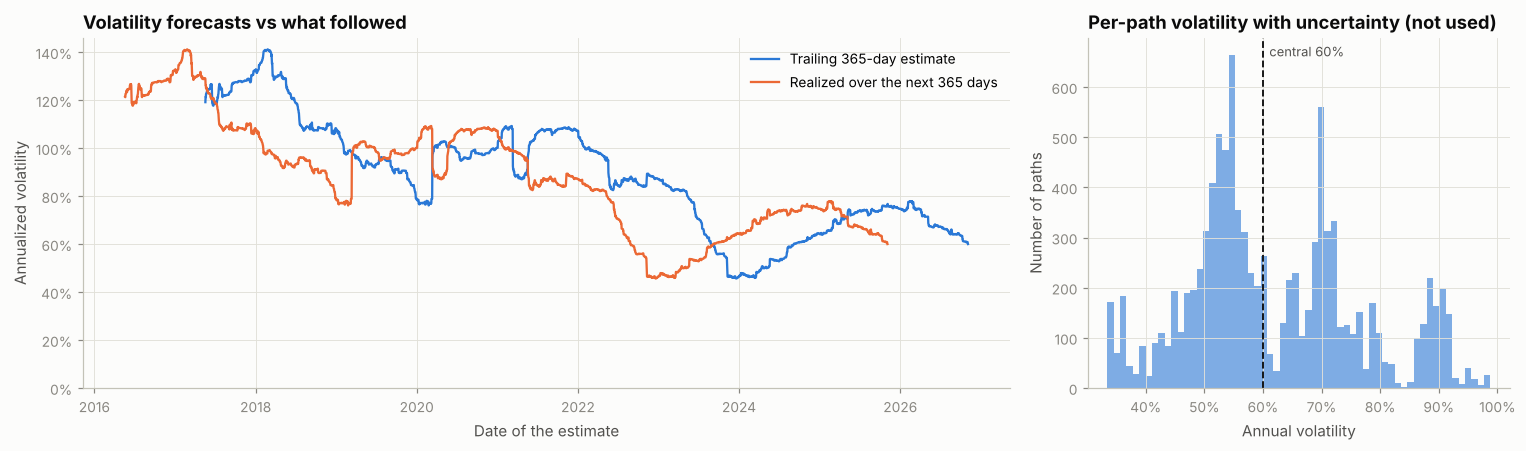

In [8]:
def vol_forecast_errors(returns: pd.Series, lookback: int, horizon: int = 365) -> pd.Series:
    """log(realized vol over the next `horizon` days / trailing `lookback`-day estimate).
    Indexed by the date the error became *known* (estimate date + horizon), so it can be used without look-ahead."""
    trailing = returns.rolling(lookback).std()
    forward = returns.rolling(horizon).std().shift(-horizon)      # std of returns t+1 .. t+horizon
    err = np.log(forward / trailing).dropna()
    err.index = err.index + pd.Timedelta(days=horizon)
    return err


def draw_vol_multipliers(errors, n_paths: int, rng: np.random.Generator) -> np.ndarray:
    e = np.asarray(errors, float)
    return np.exp(rng.choice(e - e.mean(), size=n_paths))


vol_errors = vol_forecast_errors(log_ret, VOL_LOOKBACK_DAYS)
vol_draws = SIGMA_ANNUAL * draw_vol_multipliers(vol_errors, N_PATHS, rng_for("vol-uncertainty"))
VOL_PATHS = vol_draws if VOL_UNCERTAINTY else SIGMA_ANNUAL
DRIFT_PATHS = (DRIFT + DRIFT_SD * rng_for("drift-uncertainty").standard_normal(N_PATHS)) if DRIFT_SD > 0 else DRIFT

err_sd = vol_errors.std()
print(f"{len(vol_errors):,} daily vol-forecast errors ({VOL_LOOKBACK_DAYS}d trailing estimate vs next 365d realized). "
      f"Std of log error: {err_sd:.2f}, i.e. next year's vol is typically within ×{np.exp(-err_sd):.2f}–×{np.exp(err_sd):.2f} "
      f"of the estimate (±1σ).")
per_path_vol = vol_draws
display(pd.DataFrame({f"per-path annual volatility (VOL_UNCERTAINTY {'on' if VOL_UNCERTAINTY else 'off'})": np.percentile(per_path_vol, [5, 25, 50, 75, 95])},
                     index=["P5", "P25", "P50", "P75", "P95"]).T.style.format("{:.0%}"))

trail_est = log_ret.rolling(VOL_LOOKBACK_DAYS).std() * np.sqrt(ANN)
realized_next = (log_ret.rolling(365).std() * np.sqrt(ANN)).shift(-365)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax1.plot(trail_est.index, trail_est, color=SERIES[0], lw=1.5, label=f"Trailing {VOL_LOOKBACK_DAYS}-day estimate")
ax1.plot(realized_next.index, realized_next, color=SERIES[1], lw=1.5, label="Realized over the next 365 days")
ax1.yaxis.set_major_formatter(pct_fmt)
ax1.set_ylim(0, None)
ax1.set_title("Volatility forecasts vs what followed")
ax1.set_xlabel("Date of the estimate")
ax1.set_ylabel("Annualized volatility")
ax1.legend(loc="upper right")
ax2.hist(per_path_vol, bins=60, color=SERIES[0], alpha=0.6)
ax2.axvline(SIGMA_ANNUAL, color=INK, lw=1.2, ls="--")
ax2.annotate(f"central {SIGMA_ANNUAL:.0%}", (SIGMA_ANNUAL, 1), xycoords=("data", "axes fraction"),
             xytext=(4, -12), textcoords="offset points", fontsize=8.5, color=INK2)
ax2.xaxis.set_major_formatter(pct_fmt)
ax2.set_title(f"Per-path volatility with uncertainty ({'used' if VOL_UNCERTAINTY else 'not used'})")
ax2.set_xlabel("Annual volatility")
ax2.set_ylabel("Number of paths")
plt.tight_layout()
plt.show()

### 3.2 GBM, Student-t and block bootstrap

The Student-t degrees of freedom now come from the GARCH-t fit in section 3.3, not from raw returns. Raw returns mix two different things: genuinely fat-tailed shocks, and calm and wild periods pooled together. Fitting a t to raw returns counts both as tail thickness, which gave degrees of freedom of about 2.4, an extremely heavy tail. Fitting the tails after removing volatility clustering isolates the shock distribution.

In [9]:
def _col(x, n_paths: int) -> np.ndarray:
    """Scalar or per-path array -> column vector of shape (n_paths, 1)."""
    a = np.asarray(x, float)
    return np.full((n_paths, 1), float(a)) if a.ndim == 0 else a.reshape(n_paths, 1)


def _daily_params(drift, vol_annual, n_paths: int):
    """Per-path daily log-return mean and std, each shaped (n_paths, 1)."""
    drift, vol_annual = _col(drift, n_paths), _col(vol_annual, n_paths)
    return (drift - 0.5 * vol_annual ** 2) / ANN, vol_annual / np.sqrt(ANN)


def _resolve_vol(hist_returns, vol):
    return vol if vol is not None else float(np.std(np.asarray(hist_returns, float), ddof=1) * np.sqrt(ANN))


def _to_paths(s0: float, log_returns: np.ndarray) -> np.ndarray:
    paths = np.empty((log_returns.shape[0], log_returns.shape[1] + 1))
    paths[:, 0] = s0
    paths[:, 1:] = s0 * np.exp(np.cumsum(log_returns, axis=1))
    return paths


def simulate_gbm(s0, hist_returns, horizon, n_paths, rng, drift=0.0, vol=None, fit_returns=None):
    """Geometric Brownian motion: i.i.d. normal log returns."""
    mu_d, sd_d = _daily_params(drift, _resolve_vol(hist_returns, vol), n_paths)
    return _to_paths(s0, mu_d + sd_d * rng.standard_normal((n_paths, horizon)))


def fit_raw_t_df(returns) -> float:
    """Degrees of freedom of a t fitted straight to (standardized) raw returns, kept for comparison."""
    r = np.asarray(returns, float)
    nu, _, _ = stats.t.fit((r - r.mean()) / r.std(ddof=1))
    return float(nu)


def fit_student_t_df(returns) -> float:
    """Tail thickness of the shocks once volatility clustering is removed (from the GARCH-t fit)."""
    return fit_garch_t(returns)["nu"]


def simulate_student_t(s0, hist_returns, horizon, n_paths, rng, drift=0.0, vol=None, fit_returns=None):
    """i.i.d. Student-t log returns, scaled so the std equals `vol`."""
    nu = fit_student_t_df(hist_returns if fit_returns is None else fit_returns)
    mu_d, sd_d = _daily_params(drift, _resolve_vol(hist_returns, vol), n_paths)
    scale = sd_d * np.sqrt((nu - 2) / nu)          # Var[t_nu] = nu / (nu - 2)
    return _to_paths(s0, mu_d + scale * rng.standard_t(nu, size=(n_paths, horizon)))


def simulate_bootstrap(s0, hist_returns, horizon, n_paths, rng, drift=0.0, vol=None, fit_returns=None,
                       block=BLOCK_LENGTH):
    """Moving-block bootstrap of demeaned, standardized historical daily returns, re-scaled to `vol`."""
    r = np.asarray(hist_returns, float)
    mu_d, sd_d = _daily_params(drift, _resolve_vol(hist_returns, vol), n_paths)
    z = (r - r.mean()) / r.std(ddof=1)
    n_blocks = int(np.ceil(horizon / block))
    starts = rng.integers(0, len(z) - block + 1, size=(n_paths, n_blocks))
    idx = (starts[:, :, None] + np.arange(block)).reshape(n_paths, -1)[:, :horizon]
    return _to_paths(s0, mu_d + sd_d * z[idx])

### 3.3 GARCH-t model
In a GARCH(1,1) model, today's variance depends on yesterday's shock and yesterday's variance: `σ²ₜ = ω + α·ε²ₜ₋₁ + β·σ²ₜ₋₁`. Shocks are Student-t distributed. α sets how strongly volatility reacts to a big move, and the persistence α + β sets how slowly it decays afterwards.

**The fitting problem.** The unconstrained maximum-likelihood fit puts α + β at almost exactly 1.0 on every window from 2016, 2018, 2020 and 2022 onward. That would mean volatility shocks never fade and there is no long-run volatility level at all. In practice the likelihood is very flat in that direction: ETH's volatility level has drifted over the years, and the model reads that as permanent persistence. So the model is built in three steps:

1. **Shock shape from the MLE:** α and the tail parameter ν come from the maximum-likelihood fit. Neither changes much when persistence is constrained.
2. **Capped persistence:** α + β is set to `GARCH_PERSISTENCE`. The default of 0.95, about a two-week half-life, scored best across horizons in the section 6.1 backtest, which compares 0.95, 0.98 and 0.99.
3. **Variance cap:** a path's daily volatility can never exceed the largest daily move in the history so far. With tail parameters near ν ≈ 3, an uncapped GARCH can very occasionally spiral to infinite variance.
4. **Variance targeting:** ω is set so that the long-run volatility equals `vol`, the same central volatility the other models use.

Each simulated path starts from today's filtered variance, so a calm market starts calm, and then reverts toward the long-run level.

In [10]:
_GARCH_CACHE = {}


def fit_garch_t(returns) -> dict:
    """MLE of a zero-mean GARCH(1,1) with Student-t shocks (alpha, beta, nu). Cached."""
    r = np.asarray(returns, float)
    key = (len(r), round(float(r.sum()), 10))
    if key not in _GARCH_CACHE:
        res = arch_model((r - r.mean()) * 100, mean="Zero", vol="GARCH", p=1, q=1, dist="t",
                         rescale=False).fit(disp="off", show_warning=False)
        p = res.params
        _GARCH_CACHE[key] = {"alpha": float(p["alpha[1]"]), "beta_mle": float(p["beta[1]"]),
                             "nu": max(float(p["nu"]), 2.05), "loglik": float(res.loglikelihood)}
    return _GARCH_CACHE[key]


def garch_params(fit: dict, persistence: float):
    a = min(fit["alpha"], persistence - 0.01)
    return a, persistence - a


def garch_variance_path(returns, alpha: float, beta: float, omega: float) -> np.ndarray:
    """Filtered daily conditional variances; the last element is the forecast for the next day."""
    e = np.asarray(returns, float)
    e = e - e.mean()
    var = np.empty(len(e) + 1)
    var[0] = e[:60].var()
    for t in range(len(e)):
        var[t + 1] = omega + alpha * e[t] ** 2 + beta * var[t]
    return var


def simulate_garch_t(s0, hist_returns, horizon, n_paths, rng, drift=0.0, vol=None, fit_returns=None,
                     persistence=None):
    """GARCH(1,1)-t paths: start at today's filtered variance, revert to the long-run level set by `vol`."""
    fit = fit_garch_t(hist_returns if fit_returns is None else fit_returns)
    pers = GARCH_PERSISTENCE if persistence is None else persistence
    a, b = garch_params(fit, pers)
    nu = fit["nu"]
    drift_d = _col(drift, n_paths)[:, 0] / ANN
    v_long = (_col(_resolve_vol(hist_returns, vol), n_paths)[:, 0] / np.sqrt(ANN)) ** 2   # per-path long-run variance
    v_center = np.exp(np.mean(np.log(v_long)))
    var = np.full(n_paths, garch_variance_path(hist_returns, a, b, v_center * (1 - pers))[-1])
    omega = v_long * (1 - pers)
    var_cap = float(np.max(np.asarray(hist_returns, float) ** 2))   # never above the largest daily move seen so far
    t_scale = np.sqrt((nu - 2) / nu)
    rets = np.empty((n_paths, horizon))
    for t in range(horizon):
        eps = np.sqrt(var) * t_scale * rng.standard_t(nu, n_paths)
        rets[:, t] = drift_d - 0.5 * var + eps      # per-day convexity correction keeps E[S_T] on the drift
        var = np.minimum(omega + a * eps ** 2 + b * var, var_cap)
    return _to_paths(s0, rets)

,value
alpha (MLE),0.176
"beta (MLE, unconstrained)",0.824 -> alpha + beta = 1.0000
beta used,"0.774 (persistence 0.95, half-life 14 days)"
"nu, shock tail thickness (MLE)",3.11
Student-t df if fitted to raw returns instead,2.41
Long-run volatility (targeted),60.0%
Today's conditional volatility,61.7%


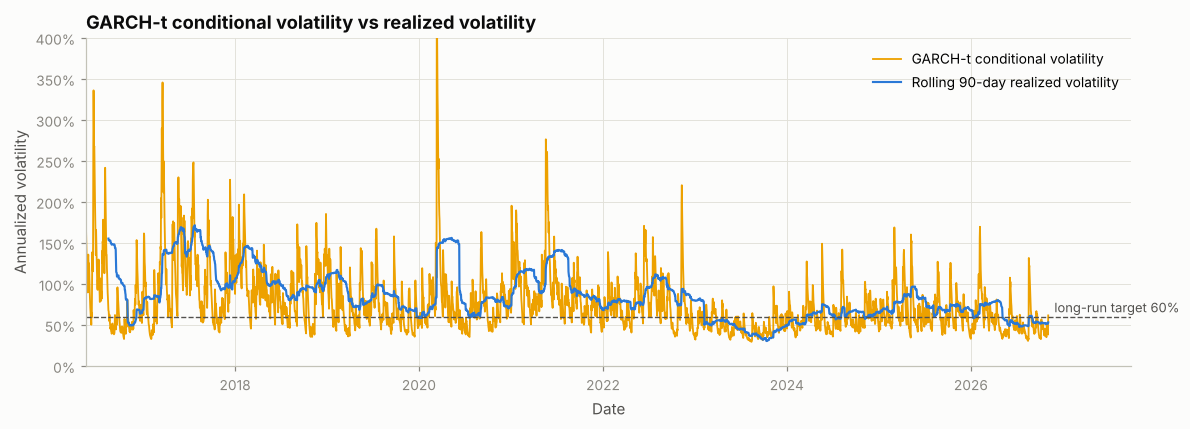

In [11]:
g = fit_garch_t(log_ret)
a_g, b_g = garch_params(g, GARCH_PERSISTENCE)
cond_var = garch_variance_path(log_ret, a_g, b_g, (SIGMA_ANNUAL / np.sqrt(ANN)) ** 2 * (1 - GARCH_PERSISTENCE))
cond_vol = pd.Series(np.sqrt(cond_var[1:] * ANN), index=log_ret.index)
garch_table = pd.Series({
    "alpha (MLE)": f"{g['alpha']:.3f}",
    "beta (MLE, unconstrained)": f"{g['beta_mle']:.3f}  ->  alpha + beta = {g['alpha'] + g['beta_mle']:.4f}",
    "beta used": f"{b_g:.3f}  (persistence {GARCH_PERSISTENCE}, half-life {np.log(0.5) / np.log(GARCH_PERSISTENCE):.0f} days)",
    "nu, shock tail thickness (MLE)": f"{g['nu']:.2f}",
    "Student-t df if fitted to raw returns instead": f"{fit_raw_t_df(log_ret):.2f}",
    "Long-run volatility (targeted)": f"{SIGMA_ANNUAL:.1%}",
    "Today's conditional volatility": f"{np.sqrt(cond_var[-1] * ANN):.1%}",
}, name="value").to_frame()
display(garch_table)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(cond_vol.index, cond_vol, color=SERIES[3], lw=1.2, label="GARCH-t conditional volatility")
ax.plot(roll90.index, roll90, color=SERIES[0], lw=1.4, label="Rolling 90-day realized volatility")
ax.axhline(SIGMA_ANNUAL, color=INK2, lw=0.9, ls="--")
ax.annotate(f"long-run target {SIGMA_ANNUAL:.0%}", (cond_vol.index[-1], SIGMA_ANNUAL), xytext=(4, 3),
            textcoords="offset points", fontsize=8.5, color=INK2)
ax.yaxis.set_major_formatter(pct_fmt)
ax.set_ylim(0, min(4, cond_vol.max() * 1.05))
ax.set_xlim(cond_vol.index[0], cond_vol.index[-1] + pd.Timedelta(days=330))
ax.set_title("GARCH-t conditional volatility vs realized volatility")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized volatility")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### 3.4 GMM regime model
The regime model works in four steps:

1. **Features.** Compute two features for every day: the rolling 30-day mean return and the rolling 30-day volatility, both annualized and standardized.
2. **Fit.** Fit Gaussian mixtures with 2 and 3 components and keep the one with the lowest BIC. Each day is labelled with its most likely component. The regimes are named by their character: the lowest-volatility regime is **calm**, and the others are **bull** or **crash** by their mean return.
3. **Transitions.** Count day-to-day regime changes to estimate a daily Markov transition matrix.
4. **Simulate.** Each simulated path starts in today's regime and switches regimes according to the transition matrix. Each day's return is drawn from the current regime's normal distribution. Regime means and volatilities are shifted and scaled together, so the long-run mix matches the common drift and volatility while the gaps between regimes are preserved.

In [12]:
_REGIME_CACHE = {}


def _name_regimes(vol_feat: np.ndarray, mean_feat: np.ndarray) -> list:
    k = len(vol_feat)
    names = [None] * k
    calm = int(np.argmin(vol_feat))
    names[calm] = "calm"
    others = sorted([i for i in range(k) if i != calm], key=lambda i: mean_feat[i])
    if len(others) == 1:
        names[others[0]] = "crash" if mean_feat[others[0]] < 0 else "bull"
    else:
        names[others[0]], names[others[-1]] = "crash", "bull"
        for i in others[1:-1]:
            names[i] = "volatile"
    return names


def _regime_features(r: pd.Series, window: int) -> pd.DataFrame:
    return pd.DataFrame({"mean_30d": r.rolling(window).mean() * ANN,
                         "vol_30d": r.rolling(window).std() * np.sqrt(ANN)}).dropna()


def fit_regime_model(hist_returns, window=GMM_WINDOW, components=GMM_COMPONENTS, seed=SEED) -> dict:
    r = pd.Series(np.asarray(hist_returns, float),
                  index=hist_returns.index if isinstance(hist_returns, pd.Series) else None)
    key = (len(r), round(float(r.sum()), 10), window, tuple(components), seed)
    if key in _REGIME_CACHE:
        return _REGIME_CACHE[key]

    feats = _regime_features(r, window)
    scaler = StandardScaler().fit(feats.to_numpy())
    X = scaler.transform(feats.to_numpy())
    fits = {k: GaussianMixture(k, covariance_type="full", n_init=5, random_state=seed).fit(X)
            for k in components}
    bic = {k: m.bic(X) for k, m in fits.items()}
    k = min(bic, key=bic.get)
    raw = fits[k].predict(X)

    vol_feat = np.array([feats["vol_30d"].to_numpy()[raw == j].mean() for j in range(k)])
    mean_feat = np.array([feats["mean_30d"].to_numpy()[raw == j].mean() for j in range(k)])
    raw_names = _name_regimes(vol_feat, mean_feat)
    order_pref = ["calm", "bull", "volatile", "crash"]
    order = sorted(range(k), key=lambda j: order_pref.index(raw_names[j]))
    remap = np.empty(k, dtype=int)
    remap[order] = np.arange(k)
    labels = remap[raw]
    names = [raw_names[j] for j in order]

    day_ret = r.loc[feats.index].to_numpy()
    mu = np.array([day_ret[labels == j].mean() for j in range(k)])
    sigma = np.array([day_ret[labels == j].std(ddof=1) for j in range(k)])

    counts = np.zeros((k, k))
    np.add.at(counts, (labels[:-1], labels[1:]), 1)
    P = counts / counts.sum(axis=1, keepdims=True)
    w, v = np.linalg.eig(P.T)
    pi = np.real(v[:, np.argmin(np.abs(w - 1))])
    pi = pi / pi.sum()

    fit = {"k": k, "bic": bic, "names": names, "labels": pd.Series(labels, index=feats.index),
           "features": feats, "mu": mu, "sigma": sigma, "P": P, "pi": pi,
           "current": int(labels[-1]), "share": np.bincount(labels, minlength=k) / len(labels),
           "gmm": fits[k], "scaler": scaler, "remap": remap, "window": window}
    _REGIME_CACHE[key] = fit
    return fit


def current_regime(fit: dict, hist_returns) -> int:
    """Classify the latest 30-day window of `hist_returns` with an already-fitted regime model."""
    r = np.asarray(hist_returns, float)[-fit["window"]:]
    x = np.array([[r.mean() * ANN, r.std(ddof=1) * np.sqrt(ANN)]])
    return int(fit["remap"][fit["gmm"].predict(fit["scaler"].transform(x))[0]])


def simulate_gmm_regime(s0, hist_returns, horizon, n_paths, rng, drift=0.0, vol=None, fit_returns=None):
    """Markov regime-switching returns; regimes from a GMM on rolling 30-day mean/vol features."""
    fit = fit_regime_model(hist_returns if fit_returns is None else fit_returns)
    mu_d, sd_d = _daily_params(drift, _resolve_vol(hist_returns, vol), n_paths)
    mu, sigma, P, pi = fit["mu"], fit["sigma"], fit["P"], fit["pi"]
    m = pi @ mu                                     # long-run (stationary) mixture mean
    v = pi @ (sigma ** 2 + mu ** 2) - m ** 2        # long-run mixture variance
    s = sd_d[:, 0] / np.sqrt(v)                     # per-path scale factor
    base = mu_d[:, 0]
    cum_p = np.cumsum(P, axis=1)
    cum_p[:, -1] = 1.0
    state = np.full(n_paths, current_regime(fit, hist_returns))
    rets = np.empty((n_paths, horizon))
    for t in range(horizon):
        u = rng.random(n_paths)
        state = (u[:, None] > cum_p[state]).sum(axis=1)
        rets[:, t] = base + (mu[state] - m) * s + sigma[state] * s * rng.standard_normal(n_paths)
    return _to_paths(s0, rets)

BIC by number of components: {2: 19430, 3: 19202} -> chose 3 regimes
Current regime (as of 2026-11-04): calm


,share of days,long-run share (stationary),avg 30d return (ann.),avg 30d vol (ann.),daily return mean,daily return std,expected stay (days)
calm,68.0%,68.4%,62.8%,64.0%,0.12%,3.50%,39
bull,10.9%,10.9%,715.3%,124.9%,1.62%,6.85%,10
crash,21.1%,20.7%,-337.3%,122.2%,-0.63%,6.54%,17


,to calm,to bull,to crash
from calm,0.974,0.012,0.014
from bull,0.078,0.898,0.024
from crash,0.045,0.013,0.943


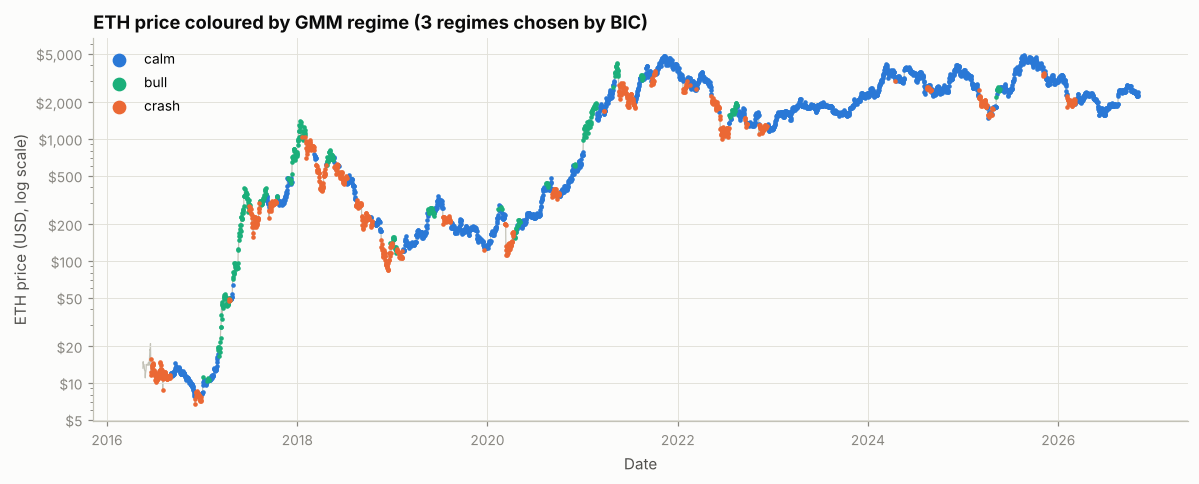

In [13]:
regimes = fit_regime_model(log_ret)
names = regimes["names"]
print("BIC by number of components:", {k: round(b) for k, b in regimes["bic"].items()},
      f"-> chose {regimes['k']} regimes")
print(f"Current regime (as of {regimes['labels'].index[-1].date()}): {names[regimes['current']]}")

regime_stats = pd.DataFrame({
    "share of days": regimes["share"],
    "long-run share (stationary)": regimes["pi"],
    "avg 30d return (ann.)": [regimes["features"]["mean_30d"][regimes["labels"] == j].mean() for j in range(regimes["k"])],
    "avg 30d vol (ann.)": [regimes["features"]["vol_30d"][regimes["labels"] == j].mean() for j in range(regimes["k"])],
    "daily return mean": regimes["mu"],
    "daily return std": regimes["sigma"],
    "expected stay (days)": 1 / (1 - np.diag(regimes["P"])),
}, index=names)
display(regime_stats.style.format({c: "{:.1%}" for c in regime_stats.columns[:4]} |
                                  {"daily return mean": "{:.2%}", "daily return std": "{:.2%}",
                                   "expected stay (days)": "{:.0f}"}))
trans = pd.DataFrame(regimes["P"], index=[f"from {n}" for n in names], columns=[f"to {n}" for n in names])
display(trans.style.format("{:.3f}").set_caption("Daily regime transition matrix"))

regime_colors = {"calm": SERIES[0], "crash": SERIES[1], "bull": SERIES[2], "volatile": SERIES[3]}
lab = regimes["labels"]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(close.index, close, color=AXIS, lw=0.8, zorder=1)
for j, n in enumerate(names):
    d = lab.index[lab == j]
    ax.scatter(d, close.loc[d], s=4, color=regime_colors[n], label=n, zorder=2)
log_price_axis(ax)
ax.set_title(f"ETH price coloured by GMM regime ({regimes['k']} regimes chosen by BIC)")
ax.set_xlabel("Date")
ax.set_ylabel("ETH price (USD, log scale)")
ax.legend(loc="upper left", markerscale=4)
plt.tight_layout()
plt.show()

### 3.5 Run all models

In [14]:
MODELS = {
    "GBM": simulate_gbm,
    "Student-t": simulate_student_t,
    "Block bootstrap": simulate_bootstrap,
    "GARCH-t": simulate_garch_t,
    "GMM regimes": simulate_gmm_regime,
}
MODEL_COLORS = dict(zip(MODELS, SERIES))

t0 = time.time()
paths = {name: fn(S0, log_ret, HORIZON_DAYS, N_PATHS, rng_for(name), drift=DRIFT_PATHS, vol=VOL_PATHS)
         for name, fn in MODELS.items()}
print(f"Simulated {len(MODELS)} models × {N_PATHS:,} paths × {HORIZON_DAYS} days in {time.time() - t0:.1f}s")
print(f"Start price ${S0:,.2f} | drift {DRIFT:.0%}" + (f" ± {DRIFT_SD:.0%}" if DRIFT_SD > 0 else "") +
      f" | central volatility {SIGMA_ANNUAL:.1%}" + (" with per-path uncertainty" if VOL_UNCERTAINTY else "") +
      f" | Student-t / GARCH shock df = {fit_student_t_df(log_ret):.2f}")

sanity = pd.DataFrame({name: {
    "realized ann. vol of simulated returns": np.diff(np.log(p), axis=1).std() * np.sqrt(ANN),
    "mean end price / S0": p[:, -1].mean() / S0,
    "median end price / S0": np.median(p[:, -1]) / S0,
} for name, p in paths.items()})
display(sanity.style.format("{:.3f}"))

Simulated 5 models × 10,000 paths × 365 days in 1.8s
Start price $2,363.24 | drift 0% | central volatility 60.0% | Student-t / GARCH shock df = 3.11


,GBM,Student-t,Block bootstrap,GARCH-t,GMM regimes
realized ann. vol of simulated returns,0.600,0.600,0.601,0.547,0.597
mean end price / S0,0.999,1.006,1.012,1.004,1.047
median end price / S0,0.826,0.842,0.827,0.878,0.832


## 4. Outputs

### 4.1 Fan charts
The shaded bands show the 5–95th and 25–75th percentiles of simulated prices on each day, and the line is the median path. The price axis is logarithmic, so equal percentage moves take equal vertical space.

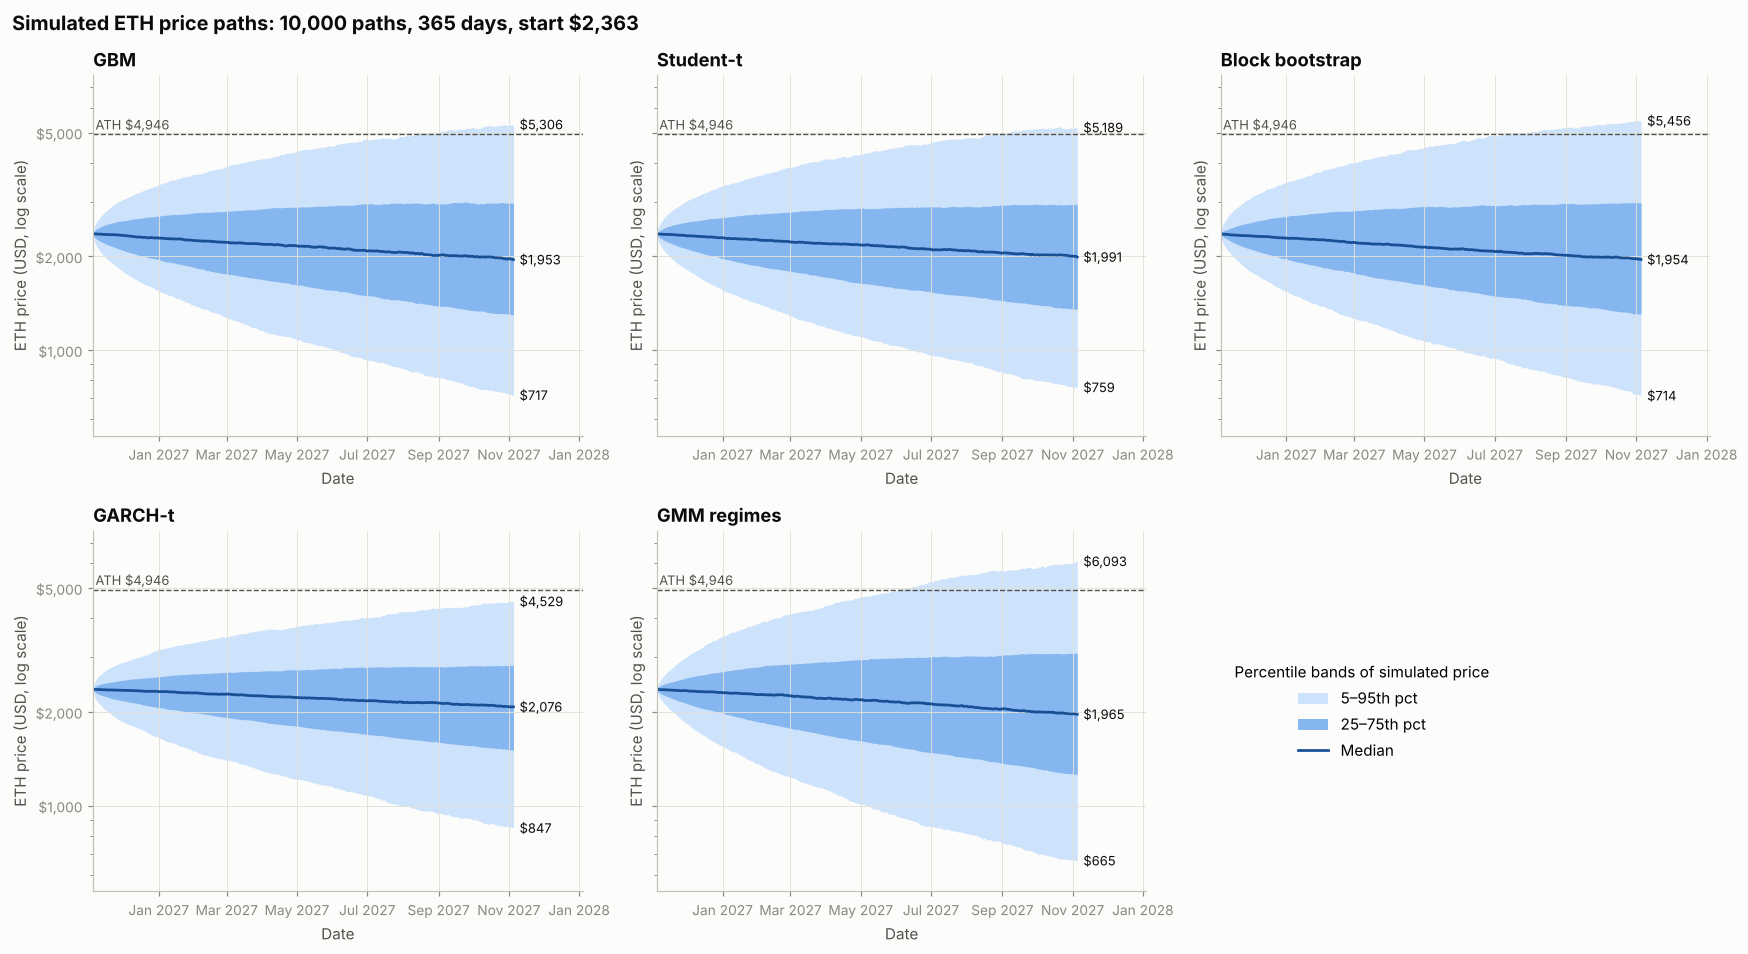

In [15]:
sim_dates = pd.date_range(TODAY, periods=HORIZON_DAYS + 1, freq="D")


def fan_chart(ax, p, title):
    q = np.percentile(p, PERCENTILES, axis=0)
    ax.fill_between(sim_dates, q[0], q[4], color=BLUE_RAMP["band_outer"], lw=0, label="5–95th pct")
    ax.fill_between(sim_dates, q[1], q[3], color=BLUE_RAMP["band_inner"], lw=0, label="25–75th pct")
    ax.plot(sim_dates, q[2], color=BLUE_RAMP["median"], lw=1.8, label="Median")
    ax.axhline(ATH_PRICE, color=INK2, lw=0.9, ls="--")
    ax.annotate(f"ATH ${ATH_PRICE:,}", (sim_dates[2], ATH_PRICE), xytext=(0, 3),
                textcoords="offset points", fontsize=8.5, color=INK2)
    for qi, v in zip([0, 2, 4], [q[0, -1], q[2, -1], q[4, -1]]):
        ax.annotate(fmt_usd(v), (sim_dates[-1], v), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=8.5, color=INK)
    log_price_axis(ax)
    ax.set_title(title)
    ax.set_ylabel("ETH price (USD, log scale)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))


n_cols = 3
n_rows = int(np.ceil((len(paths) + 1) / n_cols))          # one spare panel holds the legend
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4.4 * n_rows), sharey=True)
fan_axes = axes.flat[:len(paths)]
for ax, (name, p) in zip(fan_axes, paths.items()):
    fan_chart(ax, p, name)
    ax.set_xlabel("Date")
    ax.set_xlim(sim_dates[0], sim_dates[-1] + pd.Timedelta(days=60))
ylo = min(np.percentile(p[:, 1:], 5, axis=0).min() for p in paths.values()) * 0.8
yhi = max(np.percentile(p[:, 1:], 95, axis=0).max() for p in paths.values()) * 1.25
axes.flat[0].set_ylim(ylo, yhi)
for ax in axes.flat[len(paths):]:
    ax.axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[len(paths)].legend(handles, labels, loc="center left", fontsize=10,
                             title="Percentile bands of simulated price", title_fontsize=10)
fig.suptitle(f"Simulated ETH price paths: {N_PATHS:,} paths, {HORIZON_DAYS} days, start ${S0:,.0f}",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

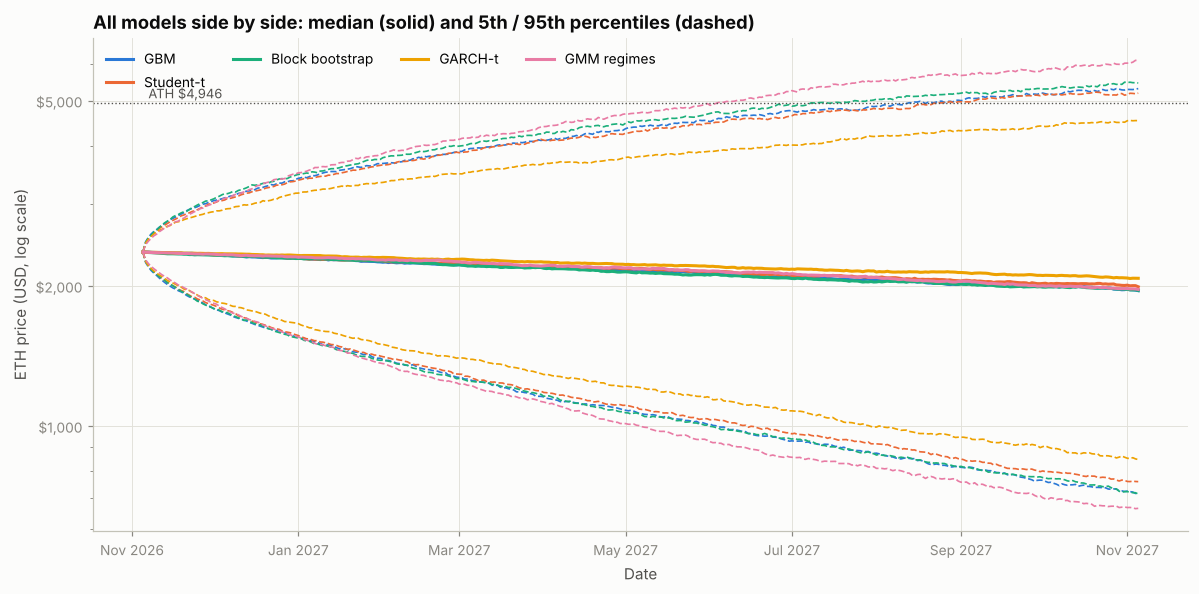

In [16]:
fig, ax = plt.subplots(figsize=(11, 5.5))
for name, p in paths.items():
    c = MODEL_COLORS[name]
    q = np.percentile(p, [5, 50, 95], axis=0)
    ax.plot(sim_dates, q[1], color=c, lw=2, label=f"{name}")
    ax.plot(sim_dates, q[0], color=c, lw=1.1, ls="--")
    ax.plot(sim_dates, q[2], color=c, lw=1.1, ls="--")
ax.axhline(ATH_PRICE, color=INK2, lw=0.9, ls=":")
ax.annotate(f"ATH ${ATH_PRICE:,}", (sim_dates[2], ATH_PRICE), xytext=(0, 3), textcoords="offset points",
            fontsize=8.5, color=INK2)
log_price_axis(ax)
ax.set_title("All models side by side: median (solid) and 5th / 95th percentiles (dashed)")
ax.set_xlabel("Date")
ax.set_ylabel("ETH price (USD, log scale)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="upper left", ncols=4)
plt.tight_layout()
plt.show()

### 4.2 End-price percentiles and implied market cap
Implied market cap is the price multiplied by today's circulating supply. Supply is held constant here, although in reality ETH issuance and burning change it slightly.

In [17]:
def end_percentiles(p: np.ndarray) -> pd.DataFrame:
    v = np.percentile(p[:, -1], PERCENTILES)
    return pd.DataFrame({"price": v, "market cap": v * SUPPLY, "vs today": v / S0 - 1},
                        index=[f"P{q}" for q in PERCENTILES])


pct_tables = {name: end_percentiles(p) for name, p in paths.items()}
end_table = pd.concat(pct_tables, axis=1)
end_table.columns.names = ["model", ""]
fmt = {}
for name in MODELS:
    fmt |= {(name, "price"): "${:,.0f}", (name, "market cap"): lambda x: fmt_bn(x), (name, "vs today"): "{:+.0%}"}
print(f"End price after {HORIZON_DAYS} days (start ${S0:,.0f}, market cap {fmt_bn(S0 * SUPPLY)})")
display(end_table.style.format(fmt))

End price after 365 days (start $2,363, market cap $289B)


### 4.3 Probability of ending above and touching price levels
- **Ends above** is the share of paths whose final price is above the level.
- **Touches** is the share of paths that reach the level on at least one day during the horizon. This is computed from the paths as a first-passage probability. Levels above today's price are touched by rising to them, and levels below by falling to them.

Paths are sampled at daily closes, so intraday wicks are missed and touch probabilities are slightly understated.

Probability of ENDING ABOVE each level after 365 days


,GBM,Student-t,Block bootstrap,GARCH-t,GMM regimes
"$1,000",86.3%,88.3%,86.2%,92.0%,84.4%
"$1,500",67.0%,69.0%,67.4%,75.4%,66.1%
"$2,000",48.4%,49.7%,48.5%,53.4%,49.0%
"$3,000",24.4%,23.8%,24.4%,21.0%,26.4%
"$4,946",6.3%,5.8%,6.7%,3.7%,8.6%
"$8,000",1.0%,1.0%,1.3%,0.7%,1.9%
"$10,000",0.4%,0.4%,0.5%,0.3%,0.8%


Probability of TOUCHING each level at any point within 365 days


,GBM,Student-t,Block bootstrap,GARCH-t,GMM regimes
"$1,000 (fall to)",22.8%,19.3%,22.6%,12.4%,25.1%
"$1,500 (fall to)",53.8%,51.2%,54.5%,39.8%,54.6%
"$2,000 (fall to)",82.2%,80.8%,82.5%,75.0%,81.3%
"$3,000 (rise to)",57.9%,55.4%,57.0%,49.1%,59.3%
"$4,946 (rise to)",13.8%,12.6%,14.7%,7.9%,17.4%
"$8,000 (rise to)",2.3%,2.0%,2.8%,1.5%,3.9%
"$10,000 (rise to)",0.7%,0.7%,1.1%,0.7%,1.7%


Median days to first touch (among paths that touch)


,GBM,Student-t,Block bootstrap,GARCH-t,GMM regimes
"$1,000 (fall to)",240,240,238,246,231
"$1,500 (fall to)",143,154,144,184,146
"$2,000 (fall to)",44,51,50,73,52
"$3,000 (rise to)",71,81,76,107,77
"$4,946 (rise to)",219,216,206,228,201
"$8,000 (rise to)",297,268,270,246,275
"$10,000 (rise to)",308,275,286,222,284


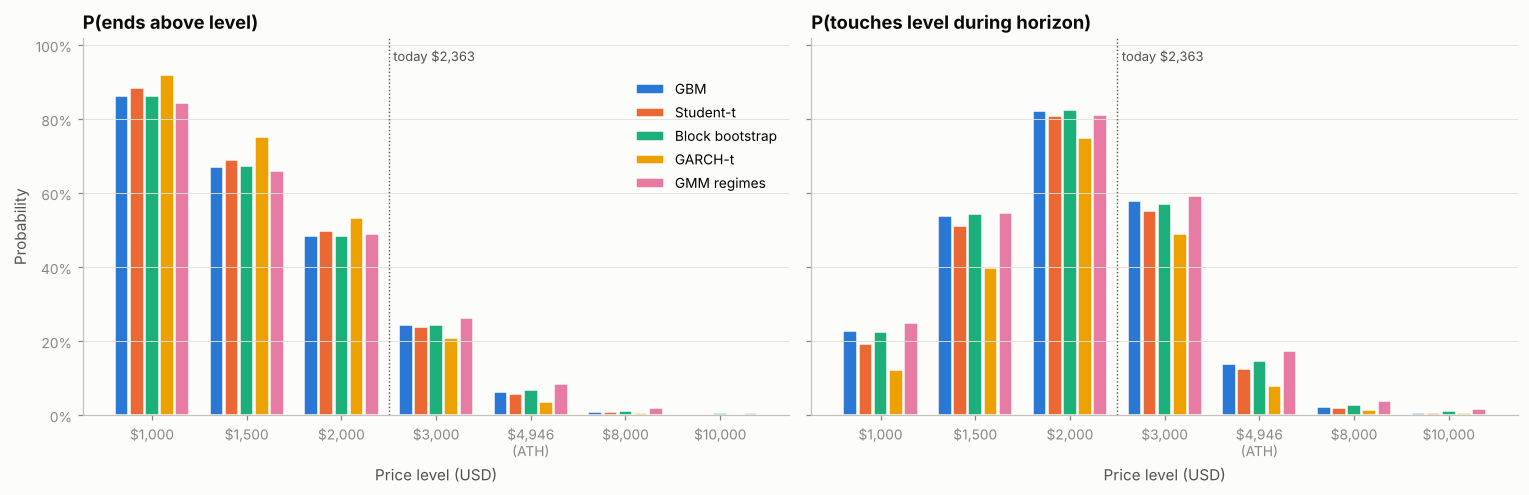

In [18]:
def threshold_probs(p: np.ndarray, thresholds) -> pd.DataFrame:
    s0, end = p[0, 0], p[:, -1]
    pmax, pmin = p[:, 1:].max(axis=1), p[:, 1:].min(axis=1)
    rows = {}
    for k in thresholds:
        touched = (pmax >= k) if k >= s0 else (pmin <= k)
        hit_day = np.where(touched, np.argmax((p[:, 1:] >= k) if k >= s0 else (p[:, 1:] <= k), axis=1) + 1, np.nan)
        rows[f"${k:,}"] = {"direction": "rise to" if k >= s0 else "fall to",
                          "P(ends above)": (end > k).mean(),
                          "P(touches)": touched.mean(),
                          "median days to first touch": np.nanmedian(hit_day) if touched.any() else np.nan}
    return pd.DataFrame(rows).T


prob_tables = {name: threshold_probs(p, THRESHOLDS) for name, p in paths.items()}
above = pd.DataFrame({n: t["P(ends above)"] for n, t in prob_tables.items()}).astype(float)
touch = pd.DataFrame({n: t["P(touches)"] for n, t in prob_tables.items()}).astype(float)
direction = prob_tables["GBM"]["direction"]
touch.index = [f"{lvl} ({d})" for lvl, d in zip(touch.index, direction)]
print(f"Probability of ENDING ABOVE each level after {HORIZON_DAYS} days")
display(above.style.format("{:.1%}"))
print(f"Probability of TOUCHING each level at any point within {HORIZON_DAYS} days")
display(touch.style.format("{:.1%}"))
days_to_touch = pd.DataFrame({n: t["median days to first touch"] for n, t in prob_tables.items()}).astype(float)
days_to_touch.index = touch.index
print("Median days to first touch (among paths that touch)")
display(days_to_touch.style.format("{:.0f}", na_rep="-"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
x = np.arange(len(THRESHOLDS))
w = 0.8 / len(MODELS)
for ax, df, title in [(axes[0], above, "P(ends above level)"), (axes[1], touch, "P(touches level during horizon)")]:
    for i, name in enumerate(MODELS):
        ax.bar(x + (i - (len(MODELS) - 1) / 2) * w, df[name].to_numpy(), width=w * 0.9,
               color=MODEL_COLORS[name], label=name, edgecolor=SURFACE, linewidth=1)
    ax.set_xticks(x, [f"${k:,}" + ("\n(ATH)" if k == ATH_PRICE else "") for k in THRESHOLDS])
    ax.yaxis.set_major_formatter(pct_fmt)
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.set_xlabel("Price level (USD)")
    ax.grid(axis="x", visible=False)
    ax.axvline(np.searchsorted(THRESHOLDS, S0) - 0.5, color=INK2, lw=0.9, ls=":")
    ax.annotate(f"today ${S0:,.0f}", (np.searchsorted(THRESHOLDS, S0) - 0.5, 1.0), xytext=(3, -2),
                textcoords="offset points", fontsize=8.5, color=INK2, va="top")
axes[0].set_ylabel("Probability")
axes[0].legend(loc="upper right", bbox_to_anchor=(1.0, 0.92))
plt.tight_layout()
plt.show()

### 4.4 Maximum drawdown along the path
For each path, the maximum drawdown is the deepest peak-to-trough fall during the horizon, counting today's price as the first peak.

,GBM,Student-t,Block bootstrap,GARCH-t,GMM regimes
expected max drawdown (mean),-52.8%,-50.6%,-52.6%,-44.1%,-53.8%
median,-52.1%,-50.0%,-51.9%,-42.1%,-53.3%
P(drawdown worse than -30%),95.4%,92.6%,94.8%,79.8%,94.5%
P(drawdown worse than -50%),55.0%,50.0%,54.9%,32.5%,57.2%
5th percentile (bad case),-77.3%,-75.6%,-76.9%,-73.6%,-79.3%


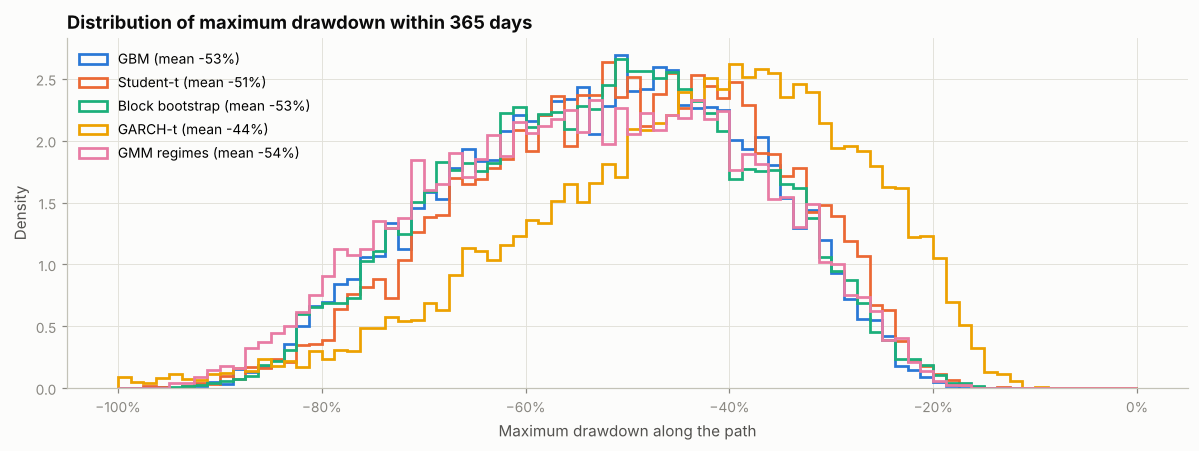

In [19]:
def max_drawdown(p: np.ndarray) -> np.ndarray:
    return (p / np.maximum.accumulate(p, axis=1) - 1).min(axis=1)


mdd = {name: max_drawdown(p) for name, p in paths.items()}
mdd_table = pd.DataFrame({name: {
    "expected max drawdown (mean)": v.mean(),
    "median": np.median(v),
    "P(drawdown worse than -30%)": (v < -0.30).mean(),
    "P(drawdown worse than -50%)": (v < -0.50).mean(),
    "5th percentile (bad case)": np.percentile(v, 5),
} for name, v in mdd.items()})
display(mdd_table.style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(11, 4.2))
bins = np.linspace(-1, 0, 81)
for name, v in mdd.items():
    ax.hist(v, bins=bins, histtype="step", lw=1.8, color=MODEL_COLORS[name], density=True,
            label=f"{name} (mean {v.mean():.0%})")
ax.xaxis.set_major_formatter(pct_fmt)
ax.set_title(f"Distribution of maximum drawdown within {HORIZON_DAYS} days")
ax.set_xlabel("Maximum drawdown along the path")
ax.set_ylabel("Density")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 5. Strategy tester
Each strategy starts with **$1 of capital** on day 0, and its outcome is the **portfolio value on the final day**. All trades execute at the daily close, with no fees, slippage or interest on cash.

- **Hold:** invest everything on day 0 and do nothing else.
- **Sell ladder:** invest everything on day 0. Sell 25% of the original ETH the first time the price closes at or above 1.5× entry, another 25% at 2×, and another 25% at 3×. Proceeds are held as cash.
- **DCA on dips:** invest 50% on day 0 and split the other 50% into 5 cash tranches. Buy one tranche each time the price closes 20% or more below its running peak. After each buy the peak resets to that day's price, so the next tranche needs a further 20% fall. Unspent cash stays as cash.

Because the DCA rule keeps part of its capital out of the market, it gives up upside in rallies in exchange for protection in sell-offs.

Final value of $1 after the horizon


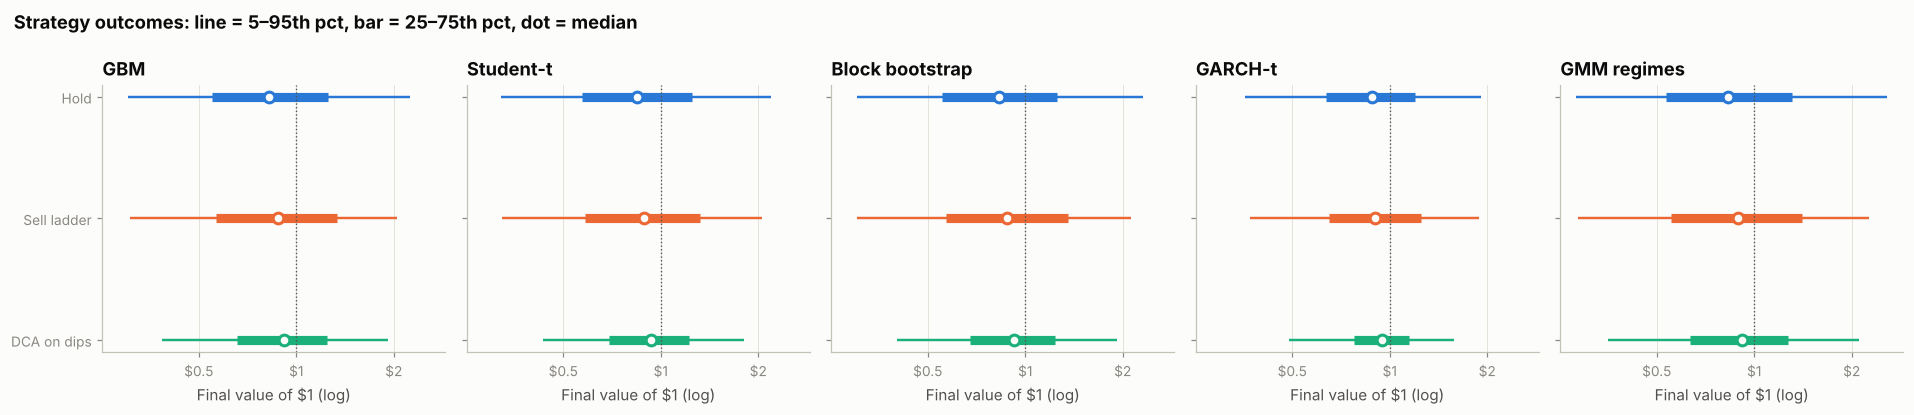

In [20]:
def strat_hold(p):
    return p[:, -1] / p[:, 0]


def strat_ladder(p, ladder=LADDER):
    rel = p / p[:, :1]                              # price relative to entry; 1 unit of ETH = $1 at entry
    eth = np.ones(len(p))
    cash = np.zeros(len(p))
    ar = np.arange(len(p))
    for mult, frac in ladder:
        hit = (rel >= mult).any(axis=1)
        first = np.argmax(rel >= mult, axis=1)
        cash += np.where(hit, frac * rel[ar, first], 0.0)
        eth -= np.where(hit, frac, 0.0)
    return cash + eth * rel[:, -1]


def strat_dca(p, initial=DCA_INITIAL_FRACTION, n_tranches=DCA_N_TRANCHES, drop=DCA_TRIGGER_DROP):
    rel = p / p[:, :1]
    tranche = (1 - initial) / n_tranches
    eth = np.full(len(p), initial)                  # in entry-price units
    cash = np.full(len(p), 1 - initial)
    left = np.full(len(p), n_tranches)
    peak = rel[:, 0].copy()
    for t in range(1, rel.shape[1]):
        price = rel[:, t]
        peak = np.maximum(peak, price)
        buy = (price <= (1 - drop) * peak) & (left > 0)
        eth[buy] += tranche / price[buy]
        cash[buy] -= tranche
        left[buy] -= 1
        peak[buy] = price[buy]
    return cash + eth * rel[:, -1]


STRATEGIES = {"Hold": strat_hold, "Sell ladder": strat_ladder, "DCA on dips": strat_dca}
STRAT_COLORS = dict(zip(STRATEGIES, SERIES))

strategy_rows, strategy_values = [], {}
for model, p in paths.items():
    hold = strat_hold(p)
    for sname, fn in STRATEGIES.items():
        v = fn(p)
        strategy_values[(model, sname)] = v
        strategy_rows.append({"model": model, "strategy": sname,
                              "P5": np.percentile(v, 5), "median": np.median(v), "P95": np.percentile(v, 95),
                              "mean": v.mean(),
                              "P(beats hold)": np.nan if sname == "Hold" else (v > hold).mean()})
strategy_table = pd.DataFrame(strategy_rows).set_index(["model", "strategy"])
print("Final value of $1 after the horizon")
display(strategy_table.style.format({"P5": "${:.2f}", "median": "${:.2f}", "P95": "${:.2f}", "mean": "${:.2f}",
                                     "P(beats hold)": "{:.1%}"}, na_rep="-"))

fig, axes = plt.subplots(1, len(MODELS), figsize=(3.3 * len(MODELS) + 1, 3.8), sharex=True, sharey=True)
for ax, model in zip(axes, MODELS):
    for i, sname in enumerate(STRATEGIES):
        v = strategy_values[(model, sname)]
        p5, p25, p50, p75, p95 = np.percentile(v, [5, 25, 50, 75, 95])
        y = len(STRATEGIES) - 1 - i
        c = STRAT_COLORS[sname]
        ax.hlines(y, p5, p95, color=c, lw=1.6)
        ax.hlines(y, p25, p75, color=c, lw=6)
        ax.plot(p50, y, "o", color=SURFACE, mec=c, mew=2, ms=7)
    ax.axvline(1.0, color=INK2, lw=0.9, ls=":")
    ax.set_title(model)
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(mticker.FixedLocator([0.25, 0.5, 1, 2, 4]))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:g}"))
    ax.xaxis.set_minor_locator(mticker.NullLocator())
    ax.set_xlabel("Final value of $1 (log)")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(STRATEGIES)), list(STRATEGIES)[::-1])
fig.suptitle("Strategy outcomes: line = 5–95th pct, bar = 25–75th pct, dot = median",
             x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

## 6. Calibration check
Do the models' forecasts match what actually happened? The backtest works like this:

1. **Pick a historical start date.** Starts are spaced every `CAL_STEP_DAYS` days.
2. **Simulate from that date's close, using only data available up to that date.**
   - Volatility comes from the trailing `VOL_LOOKBACK_DAYS`.
   - Volatility uncertainty uses only forecast errors already known by that date.
   - Slow parameters (GARCH α and ν, Student-t df, GMM regimes) are refit every `CAL_REFIT_DAYS` days on data up to the refit date.
   - Today's GARCH variance and today's regime are always computed from data up to the start date.
3. **Run every model twice,** with fixed volatility and with volatility uncertainty.
4. **Score the forecast** at each horizon in `CAL_HORIZONS`.

**What the scores mean:**

- **Coverage:** how often the realized price fell inside the central **68%** and **95%** intervals. Below nominal means the model is **overconfident**, with intervals too narrow. Above nominal means it is **underconfident**, with intervals too wide.
- **PIT histogram:** where the realized outcome ranked within the simulated distribution. A well-calibrated model gives a flat histogram. A U shape means it is overconfident, and a pile-up at the right means reality kept beating the forecast.
- **CRPS** (continuous ranked probability score): one number that rewards both calibration and sharpness, measured on log returns. **Lower is better.** It is the fairest single figure for ranking the models.

**Caveats:**

- All variants use the same start dates. The first start date is the earliest one where every variant has enough history: the longest lookback in `CAL_LOOKBACK_GRID`, plus `CAL_MIN_VOL_ERRORS` days of known volatility-forecast errors. That excludes some 2018–2019 starts.
- `VOL_OVERRIDE` is a forward-looking view, so it can't be backtested and is ignored here.
- Neighbouring start dates share most of their forecast window, so the effective sample is roughly the number of non-overlapping periods: only about 6 for the 1-year horizon, and many more at 30 days. Treat small differences as noise.

In [21]:
def crps_ensemble(x_sorted: np.ndarray, y: float) -> float:
    """CRPS of an ensemble forecast (sorted samples) for outcome y: E|X - y| - 0.5 E|X - X'|."""
    n = len(x_sorted)
    i = np.arange(1, n + 1)
    return np.mean(np.abs(x_sorted - y)) - np.sum((2 * i - n - 1) * x_sorted) / n ** 2


def variant_label(model: str, uncertain: bool) -> str:
    return f"{model} + vol uncertainty" if uncertain else model


MAIN_VARIANTS = [variant_label(m, u) for m in MODELS for u in (False, True)]
LOOKBACK_LABELS = {L: ("GBM" if L == VOL_LOOKBACK_DAYS else f"GBM, {L}d lookback") for L in CAL_LOOKBACK_GRID}
PERSIST_LABELS = {P: ("GARCH-t" if P == GARCH_PERSISTENCE else f"GARCH-t, persistence {P}") for P in CAL_PERSISTENCE_GRID}
DRIFT_SD_LABELS = {0.0: "GBM"} | {sd: f"GBM, drift sd {sd:.0%}" for sd in CAL_DRIFT_SD_GRID if sd > 0}

cal_vol_errors = vol_forecast_errors(log_ret, VOL_LOOKBACK_DAYS)
need_returns = max(max(CAL_LOOKBACK_GRID), VOL_LOOKBACK_DAYS, 500)
first_start = max(log_ret.index[need_returns - 1], cal_vol_errors.index[CAL_MIN_VOL_ERRORS - 1])
last_start = close.index[-1] - pd.Timedelta(days=min(CAL_HORIZONS))
cal_starts = pd.date_range(first_start, last_start, freq=f"{CAL_STEP_DAYS}D")
refit_dates = cal_starts[::max(1, CAL_REFIT_DAYS // CAL_STEP_DAYS)]

t0 = time.time()
records = []
for d in cal_starts:
    hist = log_ret.loc[:d]
    fit_hist = log_ret.loc[:refit_dates[refit_dates <= d][-1]]
    s_start = close.loc[d]
    horizons = [h for h in CAL_HORIZONS if d + pd.Timedelta(days=h) <= close.index[-1]]
    y = {h: np.log(close.loc[d + pd.Timedelta(days=h)] / s_start) for h in horizons}
    sigma = hist.iloc[-VOL_LOOKBACK_DAYS:].std() * np.sqrt(ANN)
    mult = draw_vol_multipliers(cal_vol_errors.loc[:d], CAL_N_PATHS, rng_for(f"cal/mult/{d.date()}"))

    jobs = [(variant_label(m, u), fn, sigma * mult if u else sigma, {})
            for m, fn in MODELS.items() for u in (False, True)]
    jobs += [(LOOKBACK_LABELS[L], simulate_gbm, hist.iloc[-L:].std() * np.sqrt(ANN), {})
             for L in CAL_LOOKBACK_GRID if L != VOL_LOOKBACK_DAYS]
    jobs += [(PERSIST_LABELS[P], simulate_garch_t, sigma, {"persistence": P})
             for P in CAL_PERSISTENCE_GRID if P != GARCH_PERSISTENCE]
    jobs += [(DRIFT_SD_LABELS[sd], simulate_gbm, sigma, {"drift_sd": sd})
             for sd in DRIFT_SD_LABELS if sd > 0]

    for label, fn, vol, kw in jobs:
        rng = rng_for(f"cal/{label}/{d.date()}")
        kw = dict(kw)
        drift = DRIFT + kw.pop("drift_sd") * rng.standard_normal(CAL_N_PATHS) if "drift_sd" in kw else DRIFT
        p = fn(s_start, hist, max(horizons), CAL_N_PATHS, rng, drift=drift, vol=vol, fit_returns=fit_hist, **kw)
        for h in horizons:
            x = np.sort(np.log(p[:, h] / s_start))
            lo95, lo68, hi68, hi95 = np.quantile(x, [0.025, 0.16, 0.84, 0.975])
            yh = y[h]
            records.append({"variant": label, "horizon": h, "start": d, "y": yh,
                            "pit": np.searchsorted(x, yh, side="right") / len(x),
                            "in68": lo68 <= yh <= hi68, "in95": lo95 <= yh <= hi95,
                            "above95": yh > hi95, "below95": yh < lo95,
                            "crps": crps_ensemble(x, yh),
                            "lo95": lo95, "lo68": lo68, "hi68": hi68, "hi95": hi95})
cal = pd.DataFrame(records)
print(f"{len(cal_starts)} start dates from {cal_starts[0].date()} to {cal_starts[-1].date()}, "
      f"{cal['variant'].nunique()} model variants, horizons {CAL_HORIZONS}, {CAL_N_PATHS:,} paths each "
      f"({time.time() - t0:.0f}s)")

386 start dates from 2019-05-18 to 2026-10-03, 18 model variants, horizons [30, 90, 180, 365], 2,000 paths each (280s)


In [22]:
def summarize(df: pd.DataFrame) -> pd.DataFrame:
    g = df.groupby("variant", sort=False)
    return pd.DataFrame({"68% coverage": g["in68"].mean(), "95% coverage": g["in95"].mean(),
                         "missed above 95%": g["above95"].mean(), "missed below 95%": g["below95"].mean(),
                         "CRPS (lower = better)": g["crps"].mean(), "forecasts": g.size()})


def verdict(cov, nominal, tol=0.05):
    if cov < nominal - tol:
        return "overconfident (intervals too narrow)"
    if cov > nominal + tol:
        return "underconfident (intervals too wide)"
    return "roughly calibrated"


main = cal[cal["variant"].isin(MAIN_VARIANTS)]
H_LONG = max(CAL_HORIZONS)
cal_summary = summarize(main[main["horizon"] == H_LONG]).loc[MAIN_VARIANTS]
print(f"Calibration at the {H_LONG}-day horizon")
display(cal_summary.style.format({c: "{:.1%}" for c in cal_summary.columns[:4]} |
                                 {"CRPS (lower = better)": "{:.4f}", "forecasts": "{:,}"})
        .highlight_min(subset=["CRPS (lower = better)"], color="#cde2fb"))

crps_by_h = main.pivot_table(index="variant", columns="horizon", values="crps", aggfunc="mean").loc[MAIN_VARIANTS]
cov95_by_h = main.pivot_table(index="variant", columns="horizon", values="in95", aggfunc="mean").loc[MAIN_VARIANTS]
crps_rank = crps_by_h.rank(axis=0).mean(axis=1)
by_h = pd.concat({"CRPS by horizon (days)": crps_by_h, "95% coverage by horizon (days)": cov95_by_h}, axis=1)
by_h[("", "avg CRPS rank")] = crps_rank
display(by_h.style.format("{:.4f}", subset="CRPS by horizon (days)")
        .format("{:.0%}", subset="95% coverage by horizon (days)")
        .format("{:.1f}", subset=[("", "avg CRPS rank")])
        .highlight_min(subset="CRPS by horizon (days)", color="#cde2fb"))

best_variant = crps_rank.idxmin()
print(f"Best variant by average CRPS rank across horizons: {best_variant}")
for label in dict.fromkeys([MAIN_VARIANTS[0], best_variant]):
    r = cal_summary.loc[label]
    side = ("above" if r["missed above 95%"] >= r["missed below 95%"] else "below")
    print(f"  {label:32s} {H_LONG}d: 68% band {r['68% coverage']:.0%} -> {verdict(r['68% coverage'], 0.68)}; "
          f"95% band {r['95% coverage']:.0%} -> {verdict(r['95% coverage'], 0.95)}; misses mostly {side} the band")

Calibration at the 365-day horizon


,68% coverage,95% coverage,missed above 95%,missed below 95%,CRPS (lower = better),forecasts
variant,,,,,,
GBM,55.9%,82.8%,17.2%,0.0%,0.6600,338
GBM + vol uncertainty,55.0%,82.8%,17.2%,0.0%,0.6624,338
Student-t,54.4%,82.8%,17.2%,0.0%,0.6599,338
Student-t + vol uncertainty,53.0%,83.1%,16.9%,0.0%,0.6647,338
Block bootstrap,59.2%,84.0%,16.0%,0.0%,0.6558,338
Block bootstrap + vol uncertainty,58.9%,84.0%,16.0%,0.0%,0.6603,338
GARCH-t,48.2%,82.5%,17.5%,0.0%,0.6295,338
GARCH-t + vol uncertainty,49.1%,82.5%,17.5%,0.0%,0.6317,338
GMM regimes,62.4%,84.6%,15.4%,0.0%,0.6585,338


Best variant by average CRPS rank across horizons: GBM
  GBM                              365d: 68% band 56% -> overconfident (intervals too narrow); 95% band 83% -> overconfident (intervals too narrow); misses mostly above the band


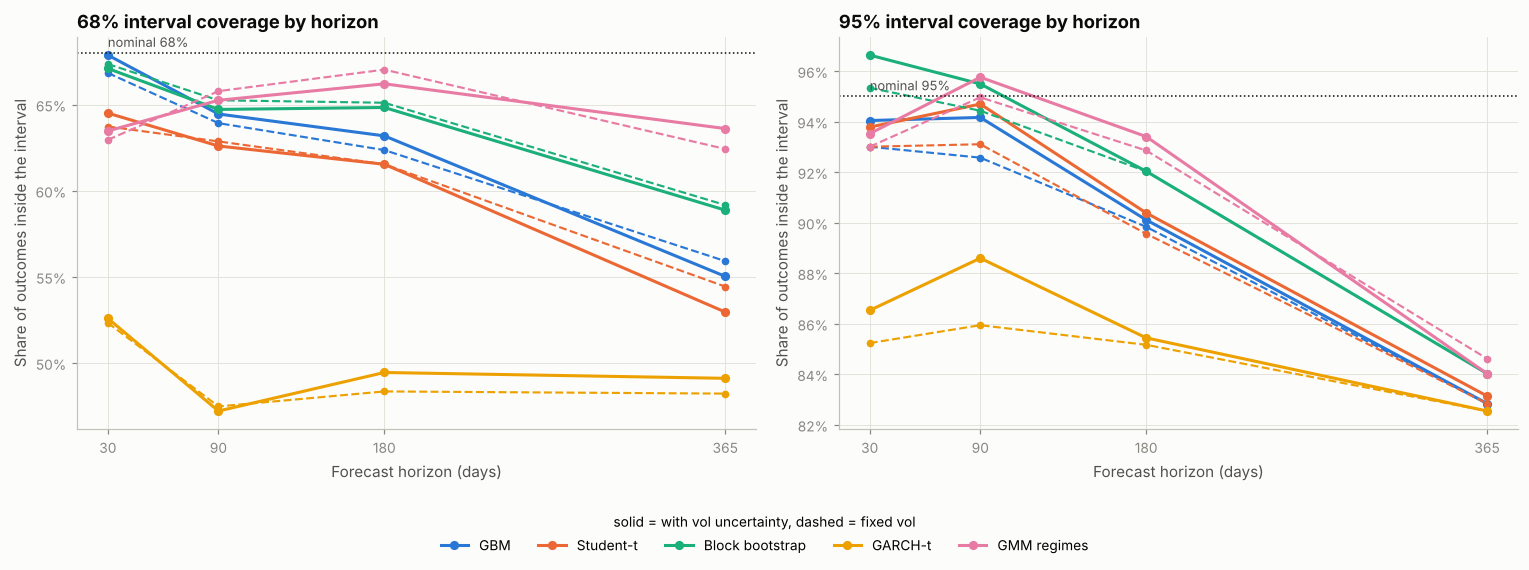

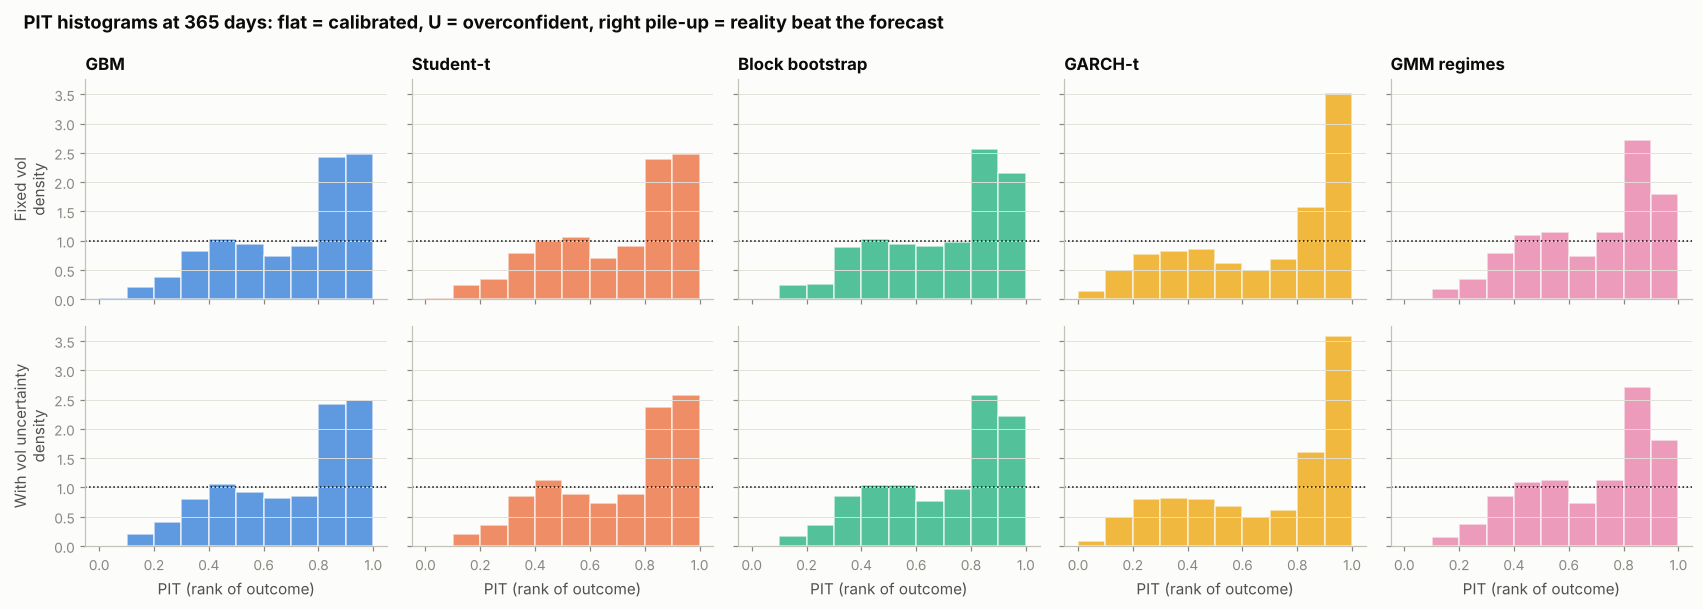

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharex=True)
for ax, col, nominal in [(axes[0], "in68", 0.68), (axes[1], "in95", 0.95)]:
    cov_h = main.pivot_table(index="horizon", columns="variant", values=col, aggfunc="mean")
    for m in MODELS:
        ax.plot(cov_h.index, cov_h[m], color=MODEL_COLORS[m], lw=1.4, ls="--", marker="o", ms=4)
        ax.plot(cov_h.index, cov_h[variant_label(m, True)], color=MODEL_COLORS[m], lw=2, marker="o", ms=5,
                label=m)
    ax.axhline(nominal, color=INK, lw=1, ls=":")
    ax.annotate(f"nominal {nominal:.0%}", (CAL_HORIZONS[0], nominal), xytext=(0, 4), textcoords="offset points",
                fontsize=8.5, color=INK2)
    ax.set_xticks(CAL_HORIZONS)
    ax.yaxis.set_major_formatter(pct_fmt)
    ax.set_title(f"{nominal:.0%} interval coverage by horizon")
    ax.set_xlabel("Forecast horizon (days)")
    ax.set_ylabel("Share of outcomes inside the interval")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncols=len(MODELS), bbox_to_anchor=(0.5, 0.0),
           title="solid = with vol uncertainty, dashed = fixed vol", title_fontsize=9)
plt.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()

fig, axes = plt.subplots(2, len(MODELS), figsize=(3.1 * len(MODELS), 5.6), sharex=True, sharey=True)
pit_bins = np.linspace(0, 1, 11)
for col, m in enumerate(MODELS):
    for row, u in enumerate((False, True)):
        ax = axes[row, col]
        pit = main[(main["variant"] == variant_label(m, u)) & (main["horizon"] == H_LONG)]["pit"]
        ax.hist(pit, bins=pit_bins, density=True, color=MODEL_COLORS[m], alpha=0.75, edgecolor=SURFACE, lw=1)
        ax.axhline(1, color=INK, lw=1, ls=":")
        ax.set_title(m if row == 0 else "", fontsize=11)
        ax.grid(axis="x", visible=False)
        if row == 1:
            ax.set_xlabel("PIT (rank of outcome)")
    axes[0, 0].set_ylabel("Fixed vol\ndensity")
    axes[1, 0].set_ylabel("With vol uncertainty\ndensity")
fig.suptitle(f"PIT histograms at {H_LONG} days: flat = calibrated, U = overconfident, right pile-up = reality beat the forecast",
             x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
plt.tight_layout()
plt.show()

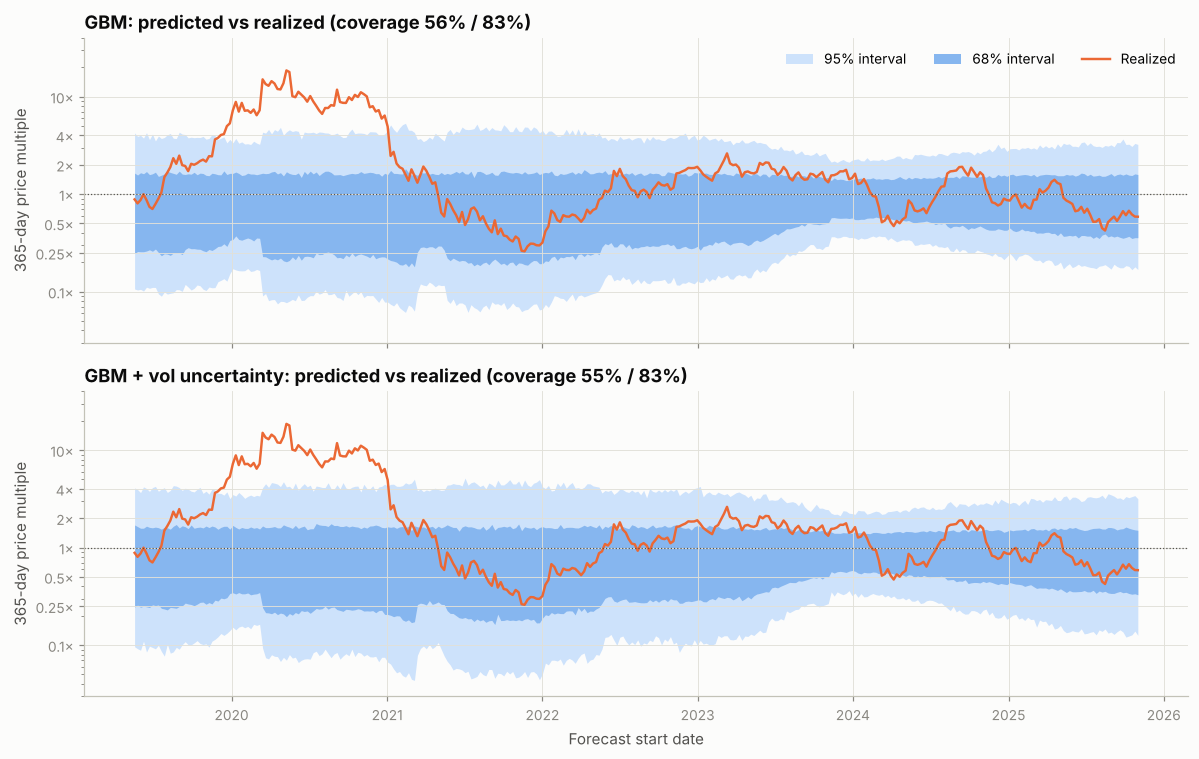

In [24]:
compare = [MAIN_VARIANTS[0], best_variant if best_variant != MAIN_VARIANTS[0] else MAIN_VARIANTS[1]]
fig, axes = plt.subplots(len(compare), 1, figsize=(11, 7), sharex=True, sharey=True)
for ax, label in zip(axes, compare):
    g = cal[(cal["variant"] == label) & (cal["horizon"] == H_LONG)]
    ax.fill_between(g["start"], np.exp(g["lo95"]), np.exp(g["hi95"]), color=BLUE_RAMP["band_outer"], lw=0,
                    label="95% interval")
    ax.fill_between(g["start"], np.exp(g["lo68"]), np.exp(g["hi68"]), color=BLUE_RAMP["band_inner"], lw=0,
                    label="68% interval")
    ax.plot(g["start"], np.exp(g["y"]), color=SERIES[1], lw=1.6, label="Realized")
    ax.axhline(1, color=INK2, lw=0.8, ls=":")
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(mticker.FixedLocator([0.1, 0.25, 0.5, 1, 2, 4, 10]))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}×"))
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())
    ax.set_ylim(0.03, 40)
    ax.set_ylabel(f"{H_LONG}-day price multiple")
    r = cal_summary.loc[label]
    ax.set_title(f"{label}: predicted vs realized (coverage {r['68% coverage']:.0%} / {r['95% coverage']:.0%})")
axes[0].legend(loc="upper right", ncols=3)
axes[-1].set_xlabel("Forecast start date")
plt.tight_layout()
plt.show()

### 6.1 Volatility window, GARCH persistence and drift uncertainty
These tables compare the same backtest scores across settings, all with fixed volatility:

- **GBM with different volatility lookback windows.** This sets `VOL_LOOKBACK_DAYS`.
- **GARCH-t with different persistence values.** This sets `GARCH_PERSISTENCE`.
- **GBM with per-path drift uncertainty** (`DRIFT_SD`). Every 95% miss in the main table is an upside miss, which suggests the uncertain quantity is drift rather than volatility. This sweep tests that directly.

With only about six independent years, prefer a setting that wins consistently across horizons over one that wins at a single horizon.

In [25]:
def sweep_table(label_map: dict, name: str, configured) -> pd.DataFrame:
    df = cal[cal["variant"].isin(label_map.values())]
    crps = df.pivot_table(index="variant", columns="horizon", values="crps", aggfunc="mean")
    cov95 = df[df["horizon"] == H_LONG].groupby("variant")["in95"].mean()
    out = crps.loc[list(label_map.values())]
    out.index = [f"{k:g}{'  (configured)' if k == configured else ''}" for k in label_map]
    out.index.name = name
    out.columns = [f"CRPS {h}d" for h in out.columns]
    out["avg CRPS rank"] = out.rank(axis=0).mean(axis=1)
    out[f"95% coverage {H_LONG}d"] = cov95.loc[list(label_map.values())].to_numpy()
    return out


sweeps = {
    "lookback": sweep_table(LOOKBACK_LABELS, "volatility lookback (days)", VOL_LOOKBACK_DAYS),
    "persistence": sweep_table(PERSIST_LABELS, "GARCH persistence", GARCH_PERSISTENCE),
    "drift sd": sweep_table(DRIFT_SD_LABELS, "drift uncertainty (annual sd)", DRIFT_SD),
}
for tbl in sweeps.values():
    crps_cols = [c for c in tbl.columns if c.startswith("CRPS")]
    display(tbl.style.format("{:.4f}", subset=crps_cols).format("{:.1f}", subset=["avg CRPS rank"])
            .format("{:.0%}", subset=[f"95% coverage {H_LONG}d"])
            .highlight_min(subset=crps_cols + ["avg CRPS rank"], color="#cde2fb"))
for key, configured in [("lookback", VOL_LOOKBACK_DAYS), ("persistence", GARCH_PERSISTENCE), ("drift sd", DRIFT_SD)]:
    best = sweeps[key]["avg CRPS rank"].idxmin().split()[0]
    print(f"Best {key} by average CRPS rank: {best} (configured: {configured:g})")

,CRPS 30d,CRPS 90d,CRPS 180d,CRPS 365d,avg CRPS rank,95% coverage 365d
volatility lookback (days),,,,,,
90,0.1367,0.2486,0.4001,0.6738,4.0,82%
180,0.1358,0.2487,0.3918,0.6603,2.8,83%
365 (configured),0.1348,0.2450,0.3836,0.6600,1.0,83%
730,0.1354,0.2488,0.3895,0.6728,2.8,83%
1095,0.1360,0.2514,0.3992,0.6986,4.5,84%


,CRPS 30d,CRPS 90d,CRPS 180d,CRPS 365d,avg CRPS rank,95% coverage 365d
GARCH persistence,,,,,,
0.95 (configured),0.1370,0.2461,0.3783,0.6295,1.5,83%
0.98,0.1390,0.2504,0.3827,0.6203,1.8,81%
0.99,0.1407,0.2563,0.3902,0.6247,2.8,76%


,CRPS 30d,CRPS 90d,CRPS 180d,CRPS 365d,avg CRPS rank,95% coverage 365d
drift uncertainty (annual sd),,,,,,
0 (configured),0.1348,0.2450,0.3836,0.6600,2.2,83%
0.5,0.1347,0.2447,0.3830,0.6557,1.0,84%
1,0.1349,0.2448,0.3850,0.6644,2.8,93%


Best lookback by average CRPS rank: 365 (configured: 365)
Best persistence by average CRPS rank: 0.95 (configured: 0.95)
Best drift sd by average CRPS rank: 0.5 (configured: 0)


## 7. Key numbers from this run
This cell recomputes the headline figures, so they stay current when the notebook is rerun.

In [26]:
lines = [f"As of {snapshot['fetched_at_utc'][:10]}: ETH ${S0:,.0f}, supply {SUPPLY / 1e6:,.1f}M, "
         f"market cap {fmt_bn(S0 * SUPPLY)}.",
         f"Central volatility {SIGMA_ANNUAL:.0%} ({'with' if VOL_UNCERTAINTY else 'without'} per-path vol uncertainty), "
         f"drift {DRIFT:.0%}, horizon {HORIZON_DAYS} days, {N_PATHS:,} paths, seed {SEED}.", ""]
for name in MODELS:
    t = pct_tables[name]
    lines.append(f"{name:16s} median {fmt_usd(t.loc['P50', 'price'])}, 90% range "
                 f"{fmt_usd(t.loc['P5', 'price'])}–{fmt_usd(t.loc['P95', 'price'])} | "
                 f"P(end > ATH) {above.loc[f'${ATH_PRICE:,}', name]:.0%}, "
                 f"P(touch ATH) {touch.iloc[THRESHOLDS.index(ATH_PRICE)][name]:.0%}, "
                 f"P(touch $1,000) {touch.iloc[0][name]:.0%} | E[max DD] {mdd[name].mean():.0%}")
lines += ["", f"Calibration at {H_LONG} days ({len(cal_starts)} start dates):"]
for label in MAIN_VARIANTS:
    r = cal_summary.loc[label]
    lines.append(f"  {label:32s} 68%: {r['68% coverage']:.0%}  95%: {r['95% coverage']:.0%}  "
                 f"CRPS {r['CRPS (lower = better)']:.4f}  (avg CRPS rank, all horizons: {crps_rank[label]:.1f})")
print("\n".join(lines))

As of 2026-11-05: ETH $2,363, supply 122.2M, market cap $289B.
Central volatility 60% (without per-path vol uncertainty), drift 0%, horizon 365 days, 10,000 paths, seed 42.

GBM              median $1,953, 90% range $717–$5,306 | P(end > ATH) 6%, P(touch ATH) 14%, P(touch $1,000) 23% | E[max DD] -53%
Student-t        median $1,991, 90% range $759–$5,189 | P(end > ATH) 6%, P(touch ATH) 13%, P(touch $1,000) 19% | E[max DD] -51%
Block bootstrap  median $1,954, 90% range $714–$5,456 | P(end > ATH) 7%, P(touch ATH) 15%, P(touch $1,000) 23% | E[max DD] -53%
GARCH-t          median $2,076, 90% range $847–$4,529 | P(end > ATH) 4%, P(touch ATH) 8%, P(touch $1,000) 12% | E[max DD] -44%
GMM regimes      median $1,965, 90% range $665–$6,093 | P(end > ATH) 9%, P(touch ATH) 17%, P(touch $1,000) 25% | E[max DD] -54%

Calibration at 365 days (386 start dates):
  GBM                              68%: 56%  95%: 83%  CRPS 0.6600  (avg CRPS rank, all horizons: 3.2)
  GBM + vol uncertainty            68%: 

## 8. Summary and limitations

*These figures come from the run on 2026-11-05: ETH at about $2,360, a market cap of about $289B, 60% volatility from the last 365 days, zero drift, and no per-path volatility uncertainty. The printout in section 7 is recomputed on every run, so check it if you have rerun the notebook.*

**What the simulations say**

- **The typical outcome is a bit lower, but the average is flat.** With no drift assumed, the median price after one year is about **$1,950–2,080**, below today's price. This is not a bearish call. For an asset this volatile, the expected price stays roughly where it is today, but more than half the paths end lower, while a minority of very large gains pull the average up.
- **The range is very wide.** The middle 50% of outcomes falls between roughly **$1,300 and $3,000**. The 90% range runs from about **$850–$4,500** for GARCH-t, the narrowest, to about **$670–$6,100** for the GMM regime model, the widest. In implied market cap that is roughly $80B to $740B.
- **Key levels:**
  - **All-time high ($4,946):** about a **4–9%** chance of ending the year above it, and about **8–17%** of touching it at some point.
  - **$10,000:** under 1%.
  - **Downside:** about a **12–25%** chance of falling to **$1,000** at some point, and about **75–83%** of trading below $2,000 at some point.
- **Expect large swings along the way.** The average path has a **peak-to-trough drawdown of about 44–54%**, and a third to over half of paths fall more than 50% from a peak at some point.

**How the models differ**

- **GBM, Student-t and the block bootstrap are nearly identical at one year.** Once they share a volatility, fat-tailed daily returns average out over 365 days.
- **The GMM regime model is the widest.** Calm, bull and crash phases persist for weeks, so long trends in either direction are more likely.
- **GARCH-t is the narrowest and starts calmest.** It starts from today's volatility of about 62% and assumes calm days follow calm days. Its typical paths are quieter, so its median is higher. Its rare blow-ups are severe but don't move the 5–95% range much.
- **The Student-t now uses ν ≈ 3.1, taken from the GARCH fit.** That replaces ν ≈ 2.4 from raw returns, which mistook volatility clustering for tail thickness.

**Strategies**

- **No rule creates expected value under zero drift.** Every strategy's mean outcome is about $1 per $1 invested.
- **Sell ladder:** it beats holding in only **18–26%** of paths. It wins when a rally fades and loses when the rally continues.
- **DCA on dips:** it beats holding in about **66–69%** of paths and has the best bad case. This is mostly because half its capital sits in cash. It reduces risk, but it isn't free return.

**Calibration: what the backtest found**

The backtest covers 386 start dates from 2019-05 to 2026-10, with every model run with and without volatility uncertainty, at horizons of 30 to 365 days.

- **At 30–90 days, the constant-volatility models are close to calibrated.** Their 95% bands contain the outcome 93–97% of the time.
- **At one year, every model is overconfident, in one direction.** The 68% bands contain only **48–62%** of outcomes, and the 95% bands only **83–85%**. **Every single 95% miss is above the band.** That is the 2020–21 run, when ETH rose more than 10× in a year. The PIT histograms show the same thing: outcomes pile up on the right.
- **Volatility uncertainty did not help.** Giving each path its own volatility, drawn from past forecast errors, left coverage unchanged and made the CRPS score slightly worse for every model. The misses come from **drift**, not from a wrong volatility. That is why the feature is now off by default.
- **Drift uncertainty does address the misses, but at a cost.**
  - A per-path drift with a standard deviation of 100% a year brings 1-year 95% coverage up to about 93%, but the forecasts lose sharpness, so CRPS gets worse at 180 and 365 days.
  - A drift sd of 50% scores marginally best, but the margin is noise.
  - If honest 1-year tails matter more to you than sharpness, set `DRIFT_SD` to 0.5–1.0.
- **A 365-day volatility window beat the 90, 180, 730 and 1,095-day windows at every horizon,** so it is now the default. This lowers the central volatility from 69% to 60%.
- **GARCH-t is a mixed result.** It has the best 1-year CRPS, but the most overconfident bands: 48% coverage for its 68% band, and only 85–89% for its 95% band at 30–90 days. Its CRPS advantage comes mainly from its higher median, which suited a period when ETH rose. That is not evidence that its spread is right. Persistence of 0.95 scored best across horizons.
- **Overall, plain GBM with a 365-day window ranks as well as anything on average.** More complex models change the shape of the risk but don't forecast better on this history.

**Limitations: read before using any of these numbers**

- **Past volatility is not future volatility.** The choice of window alone moves the central estimate between 60% and 91%. The backtest picks the 365-day window, but on only about six independent years.
- **No model here captures regulatory or macro shocks**: exchange or stablecoin failures, ETF or regulatory decisions, protocol bugs, interest-rate shocks, liquidity crises. They appear only to the extent that something similar happened between 2016 and 2026.
- **Zero drift is an assumption, not a forecast,** and the backtest shows it is where the models fail at one year. The models know nothing about fundamentals, flows or adoption. Use `DRIFT` and `DRIFT_SD` to explore other views.
- **The backtest is thin.** It covers about six independent years and is dominated by one exceptional bull run, so small differences in scores are noise. The ranking could change with the next cycle.
- **The simulation is simplified.** It uses daily closes, so touch probabilities and drawdowns miss intraday moves. The strategies ignore fees, slippage, taxes, staking yield and interest on cash. Market cap assumes today's supply. GARCH variance is capped at the largest daily move seen so far.
- **Data coverage:** the history starts on 2016-05-18, when ETH-USD began trading on Coinbase. Coinbase closes are used before 2017-11-09 and Yahoo Finance closes after.

Results are reproducible for a given `SEED` and the same cached data. A fresh live price on rerun moves the forward-looking numbers slightly, but not the backtest.